# IDC Gelar Rasa 2026 — Pengumpulan, Pemeriksaan & Analisis Data (v3, final)
**RTH vs Kualitas Udara Kota Surabaya** — satu file berisi semua perbaikan.

Jalankan dari atas ke bawah. Setiap sel menyimpan hasil ke disk, jadi setelah Colab restart cukup jalankan sel 1-2 lalu lanjut dari sel mana pun.

| Sel | Fungsi |
|---|---|
| 1-2 | Setup, konfigurasi, fungsi bantu (**parser tahun diperbaiki**) |
| 3 | Inventaris Open Data Surabaya |
| 4 | Unduh selektif + **pemutus otomatis** bila server 500 beruntun |
| 5 | (Opsional) unggah file hasil unduhan manual dari browser |
| 6 | RTH: komposisi, pembanding 2021, deteksi "tren palsu" |
| 7-8 | SPKUA (cakupan **per stasiun**) + kategori ISPU |
| 9-10 | Open-Meteo: uji batas data, lalu unduh udara + cuaca selaras |
| 11 | Analisis PM2.5: pita WHO, **pola musiman**, hujan/angin **dengan kontrol musim** |
| 12 | (Opsional) **validasi model** terhadap data stasiun |
| 13 | **Matriks ketersediaan** + irisan tahun yang layak dipakai |
| 14 | **Generator surat PPID** (otomatis dari daftar file gagal) |
| 15 | Ekspor ZIP |

**Temuan dari run sebelumnya yang sudah ditangani:** (1) tahun salah terbaca 2058/2082 → parser diperbaiki; (2) server CKAN 500 untuk file ≤2024 → pemutus + unggah manual + surat PPID; (3) SPKUA Wonorejo hanya 3-7 hari/bulan → cakupan dan perbandingan dihitung per stasiun; (4) ambang WHO 15 melampaui 97% hari → diganti pita bertingkat; (5) hujan vs PM2.5 terkecoh musim → analisis dengan kontrol per bulan; (6) Open-Meteo historis ternyata mulai **2023**.

In [ ]:
# @title 1. Setup & konfigurasi
import sys, subprocess, os, re, time, shutil
from pathlib import Path
from datetime import date, datetime, timedelta

def _pastikan(paket, impor):
    try:
        __import__(impor)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paket], check=False)

for _p, _i in [("requests", "requests"), ("pandas", "pandas"),
               ("openpyxl", "openpyxl"), ("matplotlib", "matplotlib")]:
    _pastikan(_p, _i)

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

try:
    from IPython.display import display
except Exception:
    display = print

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# ------------------------- KONFIGURASI UTAMA -------------------------
START_YEAR = 2023                  # hasil uji: PM2.5 Open-Meteo tersedia mulai 2023 (2022 kosong)
END_YEAR = date.today().year
TAHUN_MIN_UNDUH = 2021             # file CKAN bertahun < ini dilewati (tahun tak terbaca = tetap dicoba)

JALANKAN_INVENTARIS_CKAN = True
JALANKAN_UNDUH_CKAN = True
JALANKAN_OPENMETEO = True
JALANKAN_UNGGAH_MANUAL = False     # True di sel 5 bila kamu mengunduh file lewat browser

BATAS_GAGAL_BERUNTUN = 4           # hentikan percobaan sisa file pada (grup, tahun) yang sama setelah N gagal berturut-turut; 0 = nonaktif
MIN_OBS_BULAN_SPKUA = 10           # bulan-stasiun dianggap "memadai" bila >= N hari terisi

BASE_DIR = Path(os.environ.get(
    "IDC_BASE_DIR",
    "/content/IDC_RTH_Surabaya" if Path("/content").exists() else "IDC_RTH_Surabaya"))
RAW, CLEAN, ANALYSIS = BASE_DIR / "01_raw", BASE_DIR / "02_clean", BASE_DIR / "03_analysis"
DATA_LOG = RAW / "data_log.csv"

CKAN_BASES = ["https://ckan.surabaya.go.id", "https://opendata.surabaya.go.id"]

CKAN_QUERIES = [
    "jumlah luas ruang terbuka hijau",
    "taman kota dan luasnya",
    "akumulasi luasan RTH",
    "stasiun pemantauan kualitas udara ambien",
    "kualitas udara menurut lokasi pengukuran",
    "taman hutan raya",
    "kepadatan penduduk",
    "jumlah penduduk kecamatan",
    "luas wilayah kecamatan",
    "kendaraan bermotor",
]

# grup -> regex judul (urutan = prioritas klasifikasi)
GRUP_DATASET = {
    "rth_total":          r"jumlah luas ruang terbuka hijau",
    "taman_kota":         r"jumlah taman kota dan luasnya",
    "akumulasi_rth":      r"akumulasi luasan rth",
    "spkua":              r"stasiun pemantauan kualitas udara",
    "ispu_kategori":      r"kualitas udara menurut lokasi",
    "tahura_kebun_raya":  r"taman hutan raya",
    "kepadatan_penduduk": r"kepadatan penduduk",
    "penduduk_kecamatan": r"(jumlah|banyaknya) penduduk(?!.*(pindah|datang|lahir|mati|meninggal|kelompok umur))",
    "luas_wilayah":       r"luas wilayah",
    "kendaraan":          r"kendaraan bermotor",
}
GRUP_DIUNDUH = ["rth_total", "taman_kota", "akumulasi_rth", "spkua", "ispu_kategori"]
MAKS_FILE_PER_GRUP = 80
DOWNLOAD_FORMATS = {"csv", "xls", "xlsx", "json"}

# Koordinat PERKIRAAN. Resolusi model kasar -> default hanya 1 titik (sel 11 mengecek bila zona ditambah).
ZONES = {
    "pusat_kota": (-7.2575, 112.7521),
    "wonorejo_timur": (-7.3166, 112.8227),
    "kebonsari_selatan": (-7.3249, 112.7249),
    "tandes_barat": (-7.2560, 112.6830),
}
ZONA_OPENMETEO = ["pusat_kota"]

OM_AQ_URL = "https://air-quality-api.open-meteo.com/v1/air-quality"
OM_ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
OM_AQ_HOURLY = "pm2_5,pm10,nitrogen_dioxide,ozone,carbon_monoxide,sulphur_dioxide,us_aqi"
OM_WEATHER_DAILY = "temperature_2m_mean,temperature_2m_max,precipitation_sum,wind_speed_10m_max"
AQ_MODE = "auto"                   # "auto" = tahun yang lolos uji (sel 9) + jendela terbaru bila perlu; "recent" = hanya jendela terbaru
AQ_RECENT_DAYS = 90
CUACA_DARI_TAHUN = START_YEAR

# Ambang PM2.5 24 jam (ug/m3) — VERIFIKASI ulang sebelum dikutip di infografis
PM25_WHO_24H = 15        # Pedoman WHO 2021 (AQG)
PM25_IDN_24H = 55        # Baku mutu PP 22/2021 (sepengetahuan penulis kode)
PITA_PM25 = [-np.inf, 15, 25, 37.5, 50, 75, np.inf]     # AQG WHO 2021 + target antara (verifikasi)
LABEL_PITA = ["≤15 (AQG)", "15-25", "25-37,5", "37,5-50", "50-75", ">75"]

# Referensi 2021 dari berita (bukan dataset resmi) — hanya pembanding kasar
REF_2021 = {"total_rth_ha": 7358.87, "taman_jalur_hijau_ha": 1672.75,
            "sumber": "Suara Surabaya (berita); verifikasi ke dokumen DLH"}

for d in (RAW / "ckan", RAW / "openmeteo", RAW / "validasi", CLEAN, ANALYSIS):
    d.mkdir(parents=True, exist_ok=True)

GAGAL_PATH = ANALYSIS / "unduhan_gagal.csv"    # dipakai sel 4 dan sel 14
TAHUN_AQ_OK, AQ_RECENT_OK = [], False         # default; diisi ulang oleh sel 9
print("Folder kerja:", BASE_DIR)

Folder kerja: /content/IDC_RTH_Surabaya


In [ ]:
# @title 2. Fungsi bantu (parser tahun diperbaiki)
def make_session(total=2):
    # 500 sengaja tidak di-retry otomatis; retry 500 ditangani manual di unduh_resource().
    s = requests.Session()
    retry = Retry(total=total, backoff_factor=1.5,
                  status_forcelist=[429, 502, 503, 504], allowed_methods=["GET"])
    s.mount("https://", HTTPAdapter(max_retries=retry))
    s.mount("http://", HTTPAdapter(max_retries=retry))
    s.headers.update({"User-Agent": "IDC-GelarRasa-2026-riset-mahasiswa/3.0"})
    return s

def safe_name(v, maxlen=70):
    v = re.sub(r"[^\w\-. ]+", "", str(v), flags=re.UNICODE).strip()
    return re.sub(r"\s+", "_", v)[:maxlen] or "tanpa_nama"

def log_data(sumber, deskripsi, url, path, baris="", catatan=""):
    DATA_LOG.parent.mkdir(parents=True, exist_ok=True)
    header = not DATA_LOG.exists()
    pd.DataFrame([{
        "diakses_pada": datetime.now().strftime("%Y-%m-%d %H:%M"), "sumber": sumber,
        "deskripsi": deskripsi, "url": url, "file": str(path),
        "jumlah_baris": baris, "catatan": catatan}]).to_csv(
        DATA_LOG, mode="a", header=header, index=False)

BULAN_ID = {"januari": 1, "februari": 2, "maret": 3, "april": 4, "mei": 5, "juni": 6, "juli": 7,
            "agustus": 8, "september": 9, "oktober": 10, "november": 11, "desember": 12}
TAHUN_WAJAR = range(2015, date.today().year + 2)
_B = r"(?<![0-9A-Za-z])"   # batas kiri: bukan huruf/angka (mencegah menangkap potongan ID hex)
_A = r"(?![0-9A-Za-z])"    # batas kanan

def parse_periode(*teks):
    # -> (tahun, bulan). Contoh: "Data Bulan : 12-2025", "...per-har-januari-2024.csv", "(Desember)".
    # Berikan TEKS PENDEK (deskripsi, nama resource, nama berkas), jangan URL penuh yang memuat ID hex.
    kand = [str(t) for t in teks if t]
    for t in kand:
        for m in re.finditer(_B + r"(\d{1,2})-(20\d{2})" + _A, t):
            bl, th = int(m.group(1)), int(m.group(2))
            if 1 <= bl <= 12 and th in TAHUN_WAJAR:
                return th, bl
    pola_bln = "|".join(BULAN_ID)
    for t in kand:
        for m in re.finditer(r"(?i)(" + pola_bln + r")[\s_\-\.]*(20\d{2})" + _A, t):
            th = int(m.group(2))
            if th in TAHUN_WAJAR:
                return th, BULAN_ID[m.group(1).lower()]
    th_found = bl_found = None
    for t in kand:
        for m in re.finditer(_B + r"(20\d{2})" + _A, t):
            if int(m.group(1)) in TAHUN_WAJAR:
                th_found = int(m.group(1))
                break
        if th_found:
            break
    for t in kand:
        m = re.search(r"(?i)(?<![a-z])(" + pola_bln + r")(?![a-z])", t)
        if m:
            bl_found = BULAN_ID[m.group(1).lower()]
            break
    return th_found, bl_found

def bersihkan_kolom(c):
    return re.sub(r"[^\w]+", "_", str(c).strip().strip('"').lower()).strip("_")

def baca_tabel(path):
    # CSV CKAN bertitik-koma/berkutip (termasuk sel multi-baris), XLS(X), JSON.
    path = Path(path)
    suf = path.suffix.lower()
    if suf in (".xls", ".xlsx"):
        df = pd.read_excel(path)
    elif suf == ".json":
        df = pd.read_json(path)
    else:
        df = None
        for enc in ("utf-8-sig", "latin-1"):
            for sep in (";", ",", "\t", "|"):
                try:
                    tmp = pd.read_csv(path, sep=sep, encoding=enc, engine="python")
                except Exception:
                    continue
                if tmp.shape[1] > 1:
                    df = tmp
                    break
            if df is not None:
                break
        if df is None:
            df = pd.read_csv(path, sep=None, engine="python", encoding="latin-1")
    df.columns = [bersihkan_kolom(c) for c in df.columns]
    return df

def muat_grup(grup):
    frames = []
    for f in sorted((RAW / "ckan" / grup).glob("*")):
        if f.suffix.lower() not in {".csv", ".xls", ".xlsx", ".json"}:
            continue
        try:
            d = baca_tabel(f)
        except Exception as e:
            print(f"  [lewati] {f.name}: {str(e)[:100]}")
            continue
        d["_file"] = f.name
        frames.append(d)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

print("Fungsi bantu siap.")

Fungsi bantu siap.


## 3. Inventaris Open Data Surabaya
Hanya **mendaftar** dataset (tanpa unduh). Tabel "ketersediaan di portal" menunjukkan apa yang *tercatat* ada — bukan jaminan file-nya bisa diunduh (lihat sel 4).

In [ ]:
# @title 3. Inventaris CKAN
def ckan_cari_basis(session):
    for b in CKAN_BASES:
        try:
            r = session.get(f"{b}/api/3/action/status_show", timeout=25)
            if r.ok and r.json().get("success"):
                print(f"[CKAN] Portal aktif: {b}")
                return b
        except Exception as e:
            print(f"[CKAN] {b} tidak dapat diakses: {str(e)[:100]}")
    return None

def klasifikasi(judul):
    for g, pola in GRUP_DATASET.items():
        if re.search(pola, str(judul), flags=re.I):
            return g
    return None

def bangun_inventaris(hasil_per_query):
    rows = []
    for q, paket in hasil_per_query.items():
        for p in paket:
            org = (p.get("organization") or {}).get("title", "")
            for res in (p.get("resources") or []):
                url = res.get("url")
                nama_berkas = os.path.basename(url.split("?")[0]) if url else ""
                fmt = (res.get("format") or "").lower().strip()
                if not fmt and nama_berkas:
                    fmt = os.path.splitext(nama_berkas)[1].lstrip(".").lower()
                # HANYA teks pendek (bukan URL penuh) agar ID hex tidak terbaca sebagai tahun
                th, bl = parse_periode(res.get("description"), res.get("name"), nama_berkas)
                rows.append({
                    "query": q, "package_id": p.get("id"), "package_name": p.get("name"),
                    "judul": p.get("title"), "organisasi": org, "grup": klasifikasi(p.get("title")),
                    "resource_id": res.get("id"), "resource_nama": res.get("name"),
                    "deskripsi": res.get("description"), "format": fmt, "tahun": th, "bulan": bl,
                    "resource_dimodifikasi": res.get("last_modified") or res.get("metadata_modified"),
                    "url": url})
    inv = pd.DataFrame(rows)
    if not inv.empty:
        inv = inv.drop_duplicates(subset=["package_id", "resource_id"]).reset_index(drop=True)
    return inv

INV_PATH = ANALYSIS / "ckan_inventaris.csv"
inv = pd.DataFrame()

if JALANKAN_INVENTARIS_CKAN:
    sesi = make_session()
    basis = ckan_cari_basis(sesi)
    if basis:
        hasil = {}
        for q in CKAN_QUERIES:
            try:
                r = sesi.get(f"{basis}/api/3/action/package_search",
                             params={"q": q, "rows": 100}, timeout=60)
                r.raise_for_status()
                hasil[q] = r.json()["result"]["results"]
                print(f"[CKAN] '{q}': {len(hasil[q])} dataset")
            except Exception as e:
                print(f"[CKAN] '{q}' gagal: {str(e)[:100]}")
                hasil[q] = []
        inv = bangun_inventaris(hasil)
        if not inv.empty:
            inv.to_csv(INV_PATH, index=False)
            log_data("CKAN Surabaya", "Inventaris dataset", basis, INV_PATH, len(inv))
    else:
        print("[CKAN] Tidak ada portal yang merespons. Coba lagi nanti atau unduh manual.")

if inv.empty and INV_PATH.exists():
    inv = pd.read_csv(INV_PATH)
    print(f"Inventaris dimuat dari disk: {len(inv)} resource")

if not inv.empty:
    rel = inv[inv["grup"].notna()]
    print(f"\nResource relevan: {len(rel)} dari {len(inv)}")
    print("\nKETERSEDIAAN DI PORTAL (resource per grup x tahun; 'tahun?' = tahun tak terbaca):")
    tabel = pd.crosstab(rel["grup"], rel["tahun"].fillna(0).astype(int).replace(0, "tahun?"))
    display(tabel)
    print("\nJudul unik untuk grup yang TIDAK diunduh otomatis (pilih yang cocok untuk penduduk/luas kecamatan):")
    for g in ["kepadatan_penduduk", "penduduk_kecamatan", "luas_wilayah", "tahura_kebun_raya", "kendaraan"]:
        judul = sorted(set(rel[rel["grup"] == g]["judul"].dropna()))
        if judul:
            print(f"\n[{g}] {len(judul)} judul unik, contoh:")
            for x in judul[:8]:
                print("  -", x[:110])
else:
    print("Inventaris kosong.")

[CKAN] Portal aktif: https://ckan.surabaya.go.id
[CKAN] 'jumlah luas ruang terbuka hijau': 4 dataset
[CKAN] 'taman kota dan luasnya': 14 dataset
[CKAN] 'akumulasi luasan RTH': 1 dataset
[CKAN] 'stasiun pemantauan kualitas udara ambien': 4 dataset
[CKAN] 'kualitas udara menurut lokasi pengukuran': 4 dataset
[CKAN] 'taman hutan raya': 5 dataset
[CKAN] 'kepadatan penduduk': 1 dataset
[CKAN] 'jumlah penduduk kecamatan': 100 dataset
[CKAN] 'luas wilayah kecamatan': 100 dataset
[CKAN] 'kendaraan bermotor': 14 dataset

Resource relevan: 416 dari 1488

KETERSEDIAAN DI PORTAL (resource per grup x tahun; 'tahun?' = tahun tak terbaca):


tahun,2016,2021,2022,2023,2024,2025,2026,tahun?
grup,,,,,,,,
akumulasi_rth,1,0,0,0,0,0,0,0
ispu_kategori,0,0,0,12,12,0,0,6
kendaraan,0,0,24,28,24,16,30,0
kepadatan_penduduk,0,0,0,0,1,0,0,0
luas_wilayah,0,0,5,4,5,3,0,0
penduduk_kecamatan,0,2,36,28,25,18,45,0
rth_total,0,0,5,4,4,3,0,0
spkua,0,0,12,12,12,12,0,0
tahura_kebun_raya,0,0,1,0,0,0,1,13



Judul unik untuk grup yang TIDAK diunduh otomatis (pilih yang cocok untuk penduduk/luas kecamatan):

[kepadatan_penduduk] 1 judul unik, contoh:
  - Tingkat Ketahanan Pangan berdasarkan Rasio jumlah penduduk kelurahan per tenaga kesehatan terhadap kepadatan p

[penduduk_kecamatan] 17 judul unik, contoh:
  - Banyaknya penduduk non permanen yang terdata
  - Jumlah Penduduk 13-65 Tahun
  - Jumlah Penduduk Usia 60 ke atas
  - Jumlah Penduduk Usia Produktif (7-35 tahun)
  - Jumlah Penduduk Usia Produktif yang membutuhkan Pelayanan Kesehatan
  - Jumlah Penduduk berusia  tahun yang dilakukan survey aktivitas fisik
  - Jumlah Penduduk berusia  tahun yang melakukan aktivitas fisik
  - Jumlah Penduduk menurut Usia per Kelurahan Tahun 2022

[luas_wilayah] 2 judul unik, contoh:
  - Luas Wilayah Kota Surabaya
  - Tingkat Ketahanan Pangan berdasarkan Rasio luas baku lahan sawah terhadap luas wilayah kelurahan

[tahura_kebun_raya] 2 judul unik, contoh:
  - Jumlah dan Luas Taman Hutan Raya dan Kebun R

## 4. Unduh selektif (retry, host cadangan, pemutus otomatis)
Run sebelumnya: **semua file yang berhasil adalah 2025; yang gagal (HTTP 500) hampir semuanya ≤2024** — pola yang menunjukkan file lama bermasalah di sisi server. Karena itu ada **pemutus**: setelah `BATAS_GAGAL_BERUNTUN` kegagalan berturut-turut pada (grup, tahun) yang sama, sisa file grup-tahun itu dilewati tanpa membuang waktu. File yang gagal dicatat di `03_analysis/unduhan_gagal.csv` (dipakai sel 14 untuk surat PPID). Proses bisa dihentikan dan dilanjutkan.

In [ ]:
# @title 4. Unduh selektif CKAN
def unduh_resource(session, url, dest, max_coba=3):
    # Host utama: sampai max_coba kali. Host cadangan: 1 kali (path file sering 404 di host lain).
    kandidat = [(url, max_coba)]
    host = re.match(r"https?://[^/]+", url)
    for b in CKAN_BASES:
        if host and host.group(0) != b:
            kandidat.append((url.replace(host.group(0), b, 1), 1))
    alasan = []
    for u, coba in kandidat:
        nama_host = re.match(r"https?://([^/]+)", u).group(1)
        status = ""
        for i in range(coba):
            try:
                r = session.get(u, timeout=60)
                isi = r.content or b""
                if r.status_code == 200 and isi and not isi.lstrip()[:15].lower().startswith((b"<!doctype", b"<html")):
                    dest.write_bytes(isi)
                    return True, u
                status = f"HTTP {r.status_code}"
                if r.status_code == 404:
                    break
            except requests.RequestException as e:
                status = str(e)[:80]
            if i < coba - 1:
                time.sleep(1.5 * (i + 1))
        alasan.append(f"{nama_host}: {status}")
    return False, " | ".join(alasan)

def pilih_unduhan(inv):
    d = inv[inv["grup"].isin(GRUP_DIUNDUH) & inv["format"].isin(DOWNLOAD_FORMATS) & inv["url"].notna()].copy()
    d = d[d["tahun"].isna() | (d["tahun"] >= TAHUN_MIN_UNDUH)]
    d = d.sort_values(["grup", "tahun", "bulan"], ascending=[True, False, False], na_position="last")
    return d.groupby("grup", group_keys=False).head(MAKS_FILE_PER_GRUP)

if JALANKAN_UNDUH_CKAN and not inv.empty:
    target = pilih_unduhan(inv)
    print(f"Target unduhan: {len(target)} file ({', '.join(GRUP_DIUNDUH)})")
    sesi = make_session()
    ok = lewat = dilewati_pemutus = 0
    gagal = []
    beruntun = {}
    try:
        for i, (_, r) in enumerate(target.iterrows(), 1):
            folder = RAW / "ckan" / r["grup"]
            folder.mkdir(parents=True, exist_ok=True)
            th = int(r["tahun"]) if pd.notna(r["tahun"]) else None
            bl = int(r["bulan"]) if pd.notna(r["bulan"]) else None
            pref = f"{th}-{bl:02d}_" if (th and bl) else (f"{th}_" if th else "")
            dest = folder / f"{pref}{safe_name(r['resource_nama'])}_{str(r['resource_id'])[:8]}.{r['format']}"
            if dest.exists() and dest.stat().st_size > 0:
                lewat += 1
                continue
            kunci = (r["grup"], th)
            if BATAS_GAGAL_BERUNTUN and beruntun.get(kunci, 0) >= BATAS_GAGAL_BERUNTUN:
                dilewati_pemutus += 1
                gagal.append({"grup": r["grup"], "judul": r["judul"], "tahun": th, "bulan": bl,
                              "url": r["url"], "alasan": "dilewati pemutus (gagal beruntun)"})
                continue
            berhasil, info = unduh_resource(sesi, r["url"], dest)
            if berhasil:
                ok += 1
                beruntun[kunci] = 0
                log_data("CKAN Surabaya", r["judul"], info, dest)
                print(f"[{i}/{len(target)}] OK    {dest.name}")
            else:
                beruntun[kunci] = beruntun.get(kunci, 0) + 1
                gagal.append({"grup": r["grup"], "judul": r["judul"], "tahun": th, "bulan": bl,
                              "url": r["url"], "alasan": info})
                print(f"[{i}/{len(target)}] GAGAL {dest.name} ({info})")
    except KeyboardInterrupt:
        print("\nDihentikan manual. Jalankan ulang sel ini untuk melanjutkan.")
    print(f"\nSelesai: berhasil {ok}, sudah ada {lewat}, gagal {len(gagal)}, dilewati pemutus {dilewati_pemutus}")
    if gagal:
        pd.DataFrame(gagal).to_csv(GAGAL_PATH, index=False)
        print(f"Daftar gagal + URL: {GAGAL_PATH}")
        print("Langkah: (a) buka 1 URL gagal di browser; bila 500 juga -> file rusak di server;")
        print("         (b) coba unduh manual lalu unggah di sel 5; (c) ajukan ke PPID (sel 14).")
        gdf = pd.DataFrame(gagal)
        display(gdf.groupby(["grup", "tahun"], dropna=False).size().to_frame("jumlah_gagal"))
else:
    print("Unduhan dilewati (saklar mati atau inventaris kosong).")

print("\nFile terunduh per grup:")
for g in GRUP_DIUNDUH:
    p = RAW / "ckan" / g
    n = len([f for f in p.glob("*") if f.is_file()]) if p.exists() else 0
    print(f"  {g:15s}: {n} file")

Target unduhan: 106 file (rth_total, taman_kota, akumulasi_rth, spkua, ispu_kategori)
[1/106] GAGAL 2024-12_Kualitas_Udara_menurut_Lokasi_Pengukuran_per_Har_Desember_2024.csv_f4462d03.csv (ckan.surabaya.go.id: HTTP 500 | opendata.surabaya.go.id: HTTP 404)
[2/106] GAGAL 2024-11_Kualitas_Udara_menurut_Lokasi_Pengukuran_per_Har_November_2024.csv_6cf7577a.csv (ckan.surabaya.go.id: HTTP 500 | opendata.surabaya.go.id: HTTP 404)
[3/106] GAGAL 2024-10_Kualitas_Udara_menurut_Lokasi_Pengukuran_per_Har_Oktober_2024.csv_eeabd52e.csv (ckan.surabaya.go.id: HTTP 500 | opendata.surabaya.go.id: HTTP 404)
[4/106] GAGAL 2024-09_Kualitas_Udara_menurut_Lokasi_Pengukuran_per_Har_September_2024.csv_f7a5b2af.csv (ckan.surabaya.go.id: HTTP 500 | opendata.surabaya.go.id: HTTP 404)
[13/106] GAGAL 2023-12_Kualitas_Udara_menurut_Lokasi_Pengukuran_per_Har_Desember_2023.csv_50a09253.csv (ckan.surabaya.go.id: HTTP 500 | opendata.surabaya.go.id: HTTP 404)
[14/106] GAGAL 2023-11_Kualitas_Udara_menurut_Lokasi_Pengukuran

jumlah_gagal
grup          tahun               
ispu_kategori 2023.0            12
              2024.0            12
              NaN                6
rth_total     2022.0             5
              2023.0             4
              2024.0             4
              2025.0             1
spkua         2022.0            12
              2023.0            12
              2024.0            12
taman_kota    NaN               12


File terunduh per grup:
  rth_total      : 13 file
  taman_kota     : 12 file
  akumulasi_rth  : 1 file
  spkua          : 51 file
  ispu_kategori  : 30 file


In [ ]:
import pandas as pd
import requests

# 1. Muat data inventaris dari folder analisis notebook kamu
inv_path = BASE_DIR / "03_analysis" / "ckan_inventaris.csv"
gagal_path = BASE_DIR / "03_analysis" / "unduhan_gagal.csv"

if not inv_path.exists():
    print("File inventaris (ckan_inventaris.csv) tidak ditemukan. Jalankan Sel 3 dulu.")
else:
    inv = pd.read_csv(inv_path)

    # Ambil daftar resource yang relevan/gagal
    target_resources = inv.dropna(subset=["resource_id"])
    print(f"Mencoba bypass Datastore untuk {len(target_resources)} resource_id yang ada di inventaris...\n")

    berhasil_bypass = []

    for _, row in target_resources.iterrows():
        res_id = str(row["resource_id"]).strip()
        judul = row.get("judul", "Tanpa Judul")
        grup = row.get("grup", "tanpa_grup")

        url = f"https://ckan.surabaya.go.id/api/3/action/datastore_search?resource_id={res_id}&limit=5000"

        try:
            r = requests.get(url, timeout=15)
            if r.status_code == 200:
                res_json = r.json()
                if res_json.get("success"):
                    records = res_json.get("result", {}).get("records", [])
                    if records:
                        df_res = pd.DataFrame(records)
                        # Simpan hasil bypass langsung ke folder 01_raw/ckan/<grup>
                        out_dir = RAW / "ckan" / str(grup)
                        out_dir.mkdir(parents=True, exist_ok=True)
                        out_file = out_dir / f"datastore_bypass_{res_id}.csv"
                        df_res.to_csv(out_file, index=False)

                        print(f"[BERHASIL BYPASS!] {grup} | {judul[:40]} -> Saved to {out_file.name} ({len(df_res)} baris)")
                        berhasil_bypass.append(out_file)
        except Exception:
            continue

    if not berhasil_bypass:
        print("\nKesimpulan: Semua resource CKAN Pemkot memang TIDAK di-import ke Datastore oleh admin (hanya file upload mentah). API Datastore tidak bisa dipakai untuk file-file ini.")
    else:
        print(f"\nSelesai! Berhasil menyelamatkan {len(berhasil_bypass)} file lewat Datastore API. Silakan jalankan ulang Sel 6-8.")

Mencoba bypass Datastore untuk 1488 resource_id yang ada di inventaris...

[BERHASIL BYPASS!] rth_total | Jumlah Luas Ruang Terbuka Hijau -> Saved to datastore_bypass_ee3b9eda-077a-434f-a8f4-d9ff5cc62a21.csv (1 baris)
[BERHASIL BYPASS!] rth_total | Jumlah Luas Ruang Terbuka Hijau -> Saved to datastore_bypass_1ff5ec70-63e8-4355-92f6-3dcb45c82622.csv (1 baris)
[BERHASIL BYPASS!] rth_total | Jumlah Luas Ruang Terbuka Hijau -> Saved to datastore_bypass_116730a1-93f4-4c68-80af-a4ad14640be6.csv (1 baris)
[BERHASIL BYPASS!] rth_total | Jumlah Luas Ruang Terbuka Hijau -> Saved to datastore_bypass_291cdf2d-bd01-46a3-a737-9f075605d98c.csv (1 baris)
[BERHASIL BYPASS!] rth_total | Jumlah Luas Ruang Terbuka Hijau -> Saved to datastore_bypass_22034ab1-1306-4817-9e93-bb9fb4aefdc7.csv (1 baris)
[BERHASIL BYPASS!] rth_total | Jumlah Luas Ruang Terbuka Hijau -> Saved to datastore_bypass_984d7399-691e-460b-8173-fb140f5fa33c.csv (1 baris)
[BERHASIL BYPASS!] rth_total | Jumlah Luas Ruang Terbuka Hijau -> S

## 5. (Opsional) Unggah file hasil unduhan manual
Kalau kamu berhasil mengunduh file lewat browser (misalnya setelah server pulih), unggah di sini. File masuk ke folder grup yang dipilih dan otomatis ikut terbaca di sel 6-8. Set `JALANKAN_UNGGAH_MANUAL = True` di sel 1, dan pilih `GRUP_UNGGAH`.

In [ ]:
# @title 5. Unggah manual (opsional)
GRUP_UNGGAH = "taman_kota"   # salah satu: rth_total, taman_kota, akumulasi_rth, spkua, ispu_kategori

if JALANKAN_UNGGAH_MANUAL:
    try:
        from google.colab import files
        up = files.upload()
        tujuan = RAW / "ckan" / GRUP_UNGGAH
        tujuan.mkdir(parents=True, exist_ok=True)
        for nama, isi in up.items():
            (tujuan / nama).write_bytes(isi)
            log_data("Unduhan manual (browser)", nama, "", tujuan / nama, "", "diunggah manual")
            print("Tersimpan:", tujuan / nama)
    except ImportError:
        print("Fitur unggah hanya di Google Colab. Salin file ke:", RAW / "ckan" / GRUP_UNGGAH)
else:
    print("Dilewati (JALANKAN_UNGGAH_MANUAL = False).")

Dilewati (JALANKAN_UNGGAH_MANUAL = False).


## 6. RTH: komposisi, pembanding 2021, deteksi "tren palsu"

2 periode RTH ditemukan:


,periode,total_rth_ha,luas_wilayah_kota_surabaya,persen_rth_total,rth_taman_dan_jalur_hijau,persen_taman_jh
0,2025-09,7377.66,33451,22.06,1673.93,5.0
1,2025-12,7377.66,33451,22.06,1673.93,5.0



Komposisi RTH periode 2025-12:


,Kategori,Luas_ha,Persen_dari_total_RTH
0,Kawasan lindung & pesisir,4570.33,61.95
1,Taman & jalur hijau,1673.93,22.69
2,Lapangan & stadion,363.42,4.93
3,Makam,284.95,3.86
4,Fasum/fasos permukiman,220.77,2.99
5,Telaga/waduk/boezem,198.23,2.69
6,Hutan kota,66.03,0.89



Pembanding 2021 [Suara Surabaya (berita); verifikasi ke dokumen DLH]
  Total RTH      : +18.79 ha
  Taman & JH     : +1.18 ha
  Catatan: 'kawasan lindung' & 'hutan kota' bernilai sama dengan 2021 -> kemungkinan angka tetap, bukan ukur ulang tahunan.

⚠️ 2 periode ditemukan tetapi angkanya IDENTIK -> ini BUKAN tren.
   Untuk tren multi-tahun, andalkan pembanding 2021 atau minta serial historis lewat PPID (sel 14).


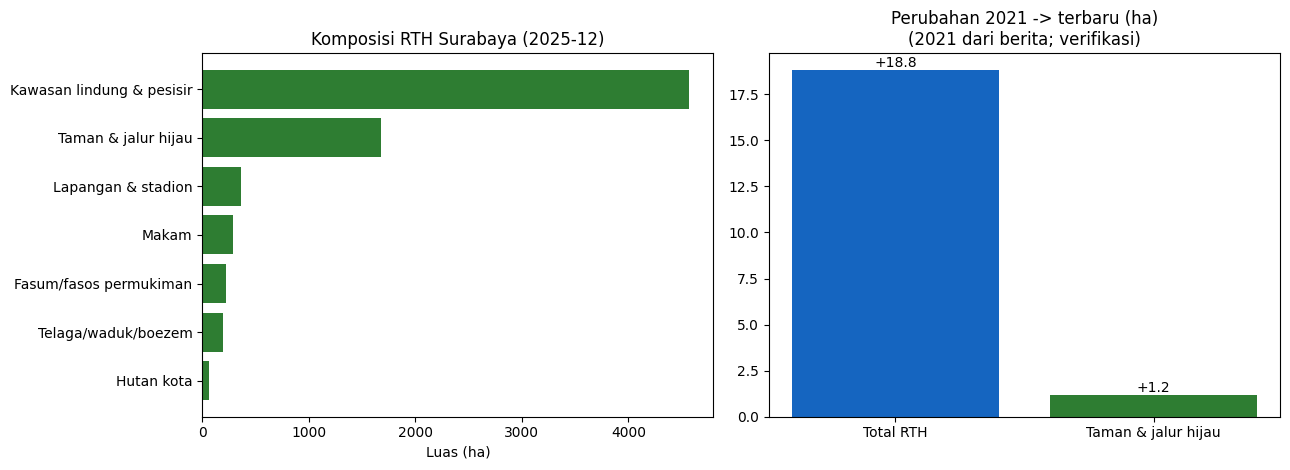

In [ ]:
# @title 6. Data RTH (Diperbaiki)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Pastikan path CLEAN terdefinisi dengan aman
CLEAN = globals().get("CLEAN", Path("02_clean"))
CLEAN.mkdir(parents=True, exist_ok=True)

# Pastikan ketersediaan REF_2021 bawaan jika belum di-set sebelumnya
REF_2021 = globals().get("REF_2021", {
    "sumber": "Berita DLH 2021",
    "total_rth_ha": 7358.87,
    "taman_jalur_hijau_ha": 1672.75
})

KOL_RTH = {
    "rth_kawasan_lindung_dan_pesisir": "Kawasan lindung & pesisir",
    "rth_taman_dan_jalur_hijau": "Taman & jalur hijau",
    "rth_lapangan_dan_stadion": "Lapangan & stadion",
    "rth_makam": "Makam",
    "rth_fasum_dan_fasos_permukiman": "Fasum/fasos permukiman",
    "rth_telagawadukboezem": "Telaga/waduk/boezem",
    "rth_hutan_kota": "Hutan kota",
}

def bangun_seri_rth(df):
    d = df.copy()
    ada = [c for c in KOL_RTH if c in d.columns]
    hilang = [c for c in KOL_RTH if c not in d.columns]
    if hilang:
        print("  [peringatan] kolom RTH tidak ditemukan:", hilang)
    for c in ada + ["luas_wilayah_kota_surabaya", "data_tahun", "data_bulan"]:
        if c in d.columns:
            d[c] = pd.to_numeric(d[c], errors="coerce")
    d = d.dropna(subset=["data_tahun"])
    d["total_rth_ha"] = d[ada].sum(axis=1, min_count=1)

    # PERBAIKAN SINTAKS: Tambahkan operator perkalian (* 100) secara presisi
    if "luas_wilayah_kota_surabaya" in d.columns:
        d["persen_rth_total"] = (d["total_rth_ha"] / d["luas_wilayah_kota_surabaya"]) * 100
        if "rth_taman_dan_jalur_hijau" in d.columns:
            d["persen_taman_jh"] = (d["rth_taman_dan_jalur_hijau"] / d["luas_wilayah_kota_surabaya"]) * 100

    d = d.sort_values(["data_tahun", "data_bulan"]).drop_duplicates(["data_tahun", "data_bulan"], keep="last")
    d["periode"] = d["data_tahun"].astype(int).astype(str) + "-" + d["data_bulan"].fillna(0).astype(int).astype(str).str.zfill(2)
    return d.reset_index(drop=True)

# Pengambilan data RTH dari grup
rth_raw = globals().get("muat_grup", lambda x: pd.DataFrame())("rth_total")
rth = pd.DataFrame()

if rth_raw.empty:
    print("Belum ada file RTH di 01_raw/ckan/rth_total. Jalankan sel 4 atau unggah manual (sel 5).")
else:
    rth = bangun_seri_rth(rth_raw)
    rth.to_csv(CLEAN / "rth_seri.csv", index=False)
    kolom_tampil = ["periode", "total_rth_ha", "luas_wilayah_kota_surabaya", "persen_rth_total",
                    "rth_taman_dan_jalur_hijau", "persen_taman_jh"]
    print(f"{len(rth)} periode RTH ditemukan:")
    display(rth[[c for c in kolom_tampil if c in rth.columns]].round(2))

    terbaru = rth.iloc[-1]
    ada = [c for c in KOL_RTH if c in rth.columns]
    komp = pd.DataFrame({
        "Kategori": [KOL_RTH[c] for c in ada],
        "Luas_ha": [terbaru[c] for c in ada]
    }).sort_values("Luas_ha", ascending=False)

    # PERBAIKAN SINTAKS: Gabungkan perkalian persentase ke dalam satu baris murni
    komp["Persen_dari_total_RTH"] = (komp["Luas_ha"] / komp["Luas_ha"].sum()) * 100
    komp.to_csv(CLEAN / "rth_komposisi_terbaru.csv", index=False)

    print(f"\nKomposisi RTH periode {terbaru['periode']}:")
    display(komp.round(2))

    # PERBAIKAN SINTAKS: Tambahkan operator pengurangan (-) yang hilang
    selisih_total = terbaru["total_rth_ha"] - REF_2021["total_rth_ha"]
    selisih_taman = terbaru.get("rth_taman_dan_jalur_hijau", 0) - REF_2021["taman_jalur_hijau_ha"]

    print(f"\nPembanding 2021 [{REF_2021['sumber']}]")
    print(f"  Total RTH      : {selisih_total:+.2f} ha")
    print(f"  Taman & JH     : {selisih_taman:+.2f} ha")
    print("  Catatan: 'kawasan lindung' & 'hutan kota' bernilai sama dengan 2021 -> kemungkinan angka tetap, bukan ukur ulang tahunan.")

    ukur = list(ada) + ["total_rth_ha"]
    tren_valid = len(rth) > 1 and len(rth[ukur].round(4).drop_duplicates()) > 1
    if len(rth) > 1 and not tren_valid:
        print(f"\n⚠️ {len(rth)} periode ditemukan tetapi angkanya IDENTIK -> ini BUKAN tren.")
        print("   Untuk tren multi-tahun, andalkan pembanding 2021 atau minta serial historis lewat PPID (sel 14).")
    if len(rth) == 1:
        print("\nHanya 1 periode tersedia -> tidak ada tren dari dataset ini.")

    # Plot Visualisasi Komposisi & Perubahan RTH
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
    ax[0].barh(komp["Kategori"][::-1], komp["Luas_ha"][::-1], color="#2e7d32")
    ax[0].set_xlabel("Luas (ha)")
    ax[0].set_title(f"Komposisi RTH Surabaya ({terbaru['periode']})")

    if tren_valid:
        ax[1].plot(rth["periode"], rth["rth_taman_dan_jalur_hijau"], marker="o", color="#2e7d32")
        ax[1].set_title("Tren luas taman & jalur hijau (ha)")
        ax[1].tick_params(axis="x", rotation=45)
    else:
        ax[1].bar(["Total RTH", "Taman & jalur hijau"], [selisih_total, selisih_taman], color=["#1565c0", "#2e7d32"])
        ax[1].set_title("Perubahan 2021 -> terbaru (ha)\n(2021 dari berita; verifikasi)")
        for i, v in enumerate([selisih_total, selisih_taman]):
            ax[1].text(i, v, f"{v:+.1f}", ha="center", va="bottom")

    plt.tight_layout()
    plt.show()

## 7. SPKUA (pemantauan udara resmi DLH) — cakupan per stasiun
> ⚠️ **Baca sebelum memakai:** dataset ini **bukan PM2.5/ISPU** (kolomnya SO₂, NO₂, CO, "NO₃", "parameter_lain"), **satuannya tidak tertulis**, dan **bukan data harian kontinu**. Di run sebelumnya Kebonsari ±24-28 hari/bulan tetapi Wonorejo hanya 3-7 hari/bulan, sehingga perbandingan antar-stasiun **tidak adil**. Grafik di bawah hanya memuat bulan-stasiun yang punya ≥ `MIN_OBS_BULAN_SPKUA` hari.

365 pengamatan | 2 stasiun | 12 bulan (2025-01 s/d 2025-12)

Ringkasan cakupan per stasiun:


,bulan_ada,bulan_memadai,rata2_hari_per_bulan,total_pengamatan
lokasi,,,,
SPKUA Kebonsari,12,10,20.2,242
SPKUA Wonorejo,12,5,10.2,123



Jenis kawasan stasiun:


,,,n_pengamatan
lokasi,kecamatan,jns_kawasan,
SPKUA Kebonsari,Jambangan,Transportasi,242
SPKUA Wonorejo,Rungkut,Permukiman,123



Rata-rata per bulan-stasiun yang memadai (>= 10 hari; SATUAN BELUM TERKONFIRMASI):


,,so2,no2,co,no3,parameter_lain
periode,lokasi,,,,,
2025-01,SPKUA Kebonsari,32.88,17.17,47.08,32.62,41.67
2025-02,SPKUA Kebonsari,39.39,21.17,55.13,33.52,37.70
2025-03,SPKUA Kebonsari,37.20,17.28,34.84,33.28,41.52
2025-04,SPKUA Kebonsari,42.32,19.72,32.76,37.76,47.68
2025-05,SPKUA Kebonsari,41.43,17.50,28.89,29.68,50.11
2025-06,SPKUA Kebonsari,37.08,23.31,20.42,36.77,53.19
2025-07,SPKUA Kebonsari,44.93,27.64,22.43,41.36,58.96
2025-08,SPKUA Wonorejo,53.74,25.35,33.48,45.65,42.57
2025-09,SPKUA Kebonsari,58.54,25.69,61.69,45.46,36.38


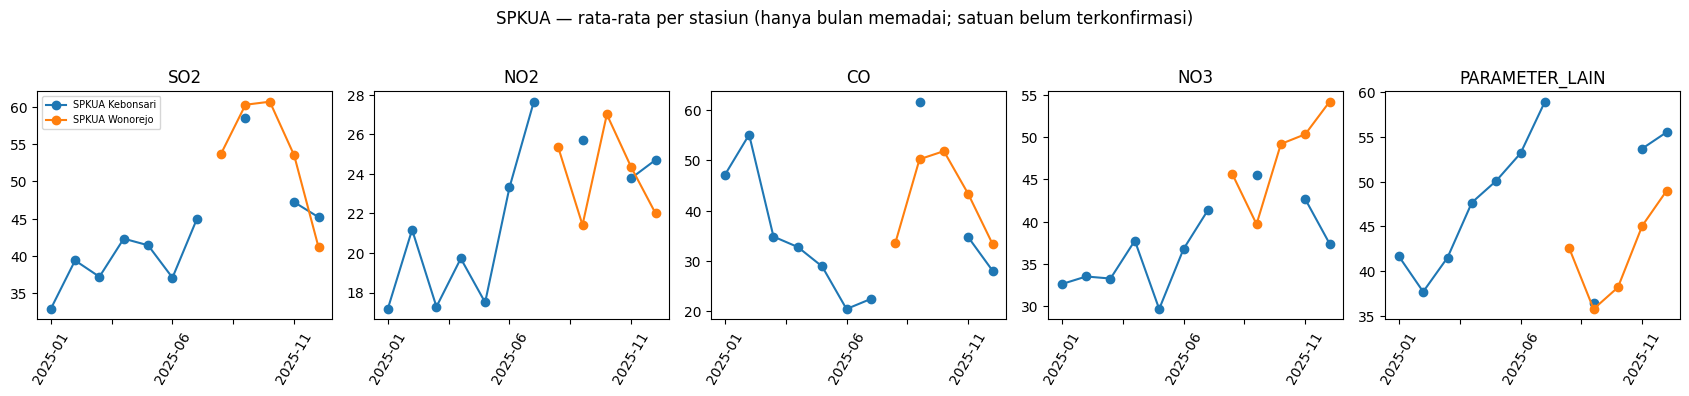

In [ ]:
# @title 7. Data SPKUA
PARAM_SPKUA = ["so2", "no2", "co", "no3", "parameter_lain"]

def siapkan_spkua(df):
    d = df.copy()
    d["waktu"] = pd.to_datetime(d["waktu"], errors="coerce")
    for p in PARAM_SPKUA:
        d[p] = pd.to_numeric(d[p], errors="coerce") if p in d.columns else np.nan
    d = d.dropna(subset=["lokasi", "waktu"])
    d = d.drop_duplicates(subset=["lokasi", "waktu"] + PARAM_SPKUA)
    d["periode"] = d["waktu"].dt.to_period("M")
    return d.reset_index(drop=True)

def cakupan_spkua(d):
    g = d.groupby(["periode", "lokasi"]).agg(
        n_pengamatan=("waktu", "count"),
        hari_unik=("waktu", lambda s: s.dt.normalize().nunique()),
        awal=("waktu", "min"), akhir=("waktu", "max")).reset_index()
    g["hari_dalam_bulan"] = g["periode"].apply(lambda p: p.days_in_month)
    g["cakupan_persen"] = (g["hari_unik"] / g["hari_dalam_bulan"] * 100).round(1)
    g["memadai"] = g["hari_unik"] >= MIN_OBS_BULAN_SPKUA
    return g

spk_raw = muat_grup("spkua")
spk = pd.DataFrame()
if spk_raw.empty:
    print("Belum ada file SPKUA di 01_raw/ckan/spkua.")
else:
    spk = siapkan_spkua(spk_raw)
    spk.assign(periode=spk["periode"].astype(str)).to_csv(CLEAN / "spkua_gabungan.csv", index=False)
    cak = cakupan_spkua(spk)
    cak.assign(periode=cak["periode"].astype(str)).to_csv(ANALYSIS / "spkua_cakupan.csv", index=False)
    print(f"{len(spk)} pengamatan | {spk['lokasi'].nunique()} stasiun | "
          f"{spk['periode'].nunique()} bulan ({spk['periode'].min()} s/d {spk['periode'].max()})")

    print("\nRingkasan cakupan per stasiun:")
    ring = cak.groupby("lokasi").agg(
        bulan_ada=("periode", "nunique"), bulan_memadai=("memadai", "sum"),
        rata2_hari_per_bulan=("hari_unik", "mean"), total_pengamatan=("n_pengamatan", "sum")).round(1)
    display(ring)
    if ring["rata2_hari_per_bulan"].max() > 2 * max(ring["rata2_hari_per_bulan"].min(), 1):
        print("⚠️ Jumlah hari terisi antar-stasiun sangat timpang -> JANGAN bandingkan stasiun secara langsung.")
        print("   Tanyakan ke DLH (sel 14) mengapa frekuensi pengukuran berbeda.")

    if "jns_kawasan" in spk.columns:
        print("\nJenis kawasan stasiun:")
        display(spk.groupby(["lokasi", "kecamatan", "jns_kawasan"]).size().to_frame("n_pengamatan"))

    hari = spk.groupby(["periode", "lokasi"])["waktu"].agg(lambda s: s.dt.normalize().nunique())
    pv = spk.groupby(["periode", "lokasi"])[PARAM_SPKUA].mean()
    pv_ok = pv[hari.reindex(pv.index) >= MIN_OBS_BULAN_SPKUA]
    print(f"\nRata-rata per bulan-stasiun yang memadai (>= {MIN_OBS_BULAN_SPKUA} hari; SATUAN BELUM TERKONFIRMASI):")
    display(pv_ok.round(2))

    if pv_ok.empty:
        print("Tidak ada bulan-stasiun yang memadai untuk digrafikkan.")
    else:
        fig, axes = plt.subplots(1, len(PARAM_SPKUA), figsize=(3.4 * len(PARAM_SPKUA), 3.8))
        for ax, p in zip(axes, PARAM_SPKUA):
            t = pv_ok[p].unstack("lokasi")
            t.index = t.index.astype(str)
            t.plot(ax=ax, kind="bar" if len(t) == 1 else "line", marker=None if len(t) == 1 else "o", legend=False)
            ax.set_title(p.upper()); ax.set_xlabel("")
            ax.tick_params(axis="x", rotation=60)
        axes[0].legend(fontsize=7)
        fig.suptitle("SPKUA — rata-rata per stasiun (hanya bulan memadai; satuan belum terkonfirmasi)", y=1.03)
        plt.tight_layout()
        plt.show()

In [ ]:
# @title 8. Kategori ISPU per hari (Diperbaiki & Resilien terhadap Error HTTP 500)
import pandas as pd
from pathlib import Path

# Pastikan variabel direktori tersedia
CLEAN = globals().get("CLEAN", Path("02_clean"))
CLEAN.mkdir(parents=True, exist_ok=True)

# Fungsi muat_grup aman (jika belum didefinisikan sebelumnya)
muat_grup = globals().get("muat_grup", lambda x: pd.DataFrame())

# 1. Muat dataset utama
isp = muat_grup("ispu_kategori")

# 2. Cek ketersediaan data & penanganan Fallback
if isp.empty:
    print("⚠️ Belum ada file di 01_raw/ckan/ispu_kategori ('Kualitas Udara menurut Lokasi Pengukuran per Hari').")
    print("   Penyebab: Server CKAN Pemkot mengalami HTTP 500 pada eksekusi sebelumnya.")

    # Coba Fallback: Periksa apakah ada data SPKUA harian lain yang bisa dimuat
    spkua_alt = muat_grup("spkua_harian")
    if not spkua_alt.empty:
        print("\n🔄 [Fallback] Ditemukan data alternatif dari 'spkua_harian'. Menggunakan data SPKUA tersebut...")
        spkua_alt.to_csv(CLEAN / "spkua_harian_gabungan.csv", index=False)
        print(f"   Terload {len(spkua_alt)} baris dari {spkua_alt['_file'].nunique()} file SPKUA. Contoh data:")
        display(spkua_alt.head(5))
    else:
        print("💡 Rekomendasi: Anda dapat mengunggah berkas ISPU CSV manual ke folder '01_raw/ckan/ispu_kategori/' atau gunakan Surat PPID (Sel 14) untuk mengajukan permintaan data mentah.")

else:
    # 3. Pemprosesan jika data ISPU berhasil diunduh
    # Bersihkan nama kolom otomatis untuk fleksibilitas
    isp.columns = [str(c).strip().lower() for c in isp.columns]

    # Simpan data gabungan ke direktori clean
    file_out = CLEAN / "ispu_kategori_gabungan.csv"
    isp.to_csv(file_out, index=False)

    n_files = isp["_file"].nunique() if "_file" in isp.columns else "beberapa"
    print(f"✅ Berhasil memuat {len(isp)} baris data dari {n_files} berkas ISPU.")
    print("Struktur data ISPU Kategori:")
    display(isp.head(12))

    # Ringkasan Kategori ISPU jika kolom tersedia
    kol_kategori = [c for c in isp.columns if "kategori" in c or "ispu" in c or "kondisi" in c]
    if kol_kategori:
        print("\n📊 Ringkasan Jumlah Hari per Kategori (Keseluruhan Data):")
        display(isp[kol_kategori[0]].value_counts().to_frame("Jumlah Hari"))
        print("\nBila tabel memuat jumlah hari per kategori ISPU per bulan, itu data terbaik untuk indikator 'hari tidak sehat'.")

✅ Berhasil memuat 198 baris data dari 30 berkas ISPU.
Struktur data ISPU Kategori:


,id,nilai_psi,kualitas_udara_ispu,januari,februari,maret,april,mei,juni,juli,agustus,september,oktober,november,desember,jumlah,,_file,jan,feb,mar,apr,agt,sept,okt,nop,des
0,1,0 - 50,Baik,0.0,0.0,14.0,17.0,13.0,11.0,0.0,0.0,0.0,0.0,0.0,0.0,55.0,3022.0,datastore_bypass_029ac566-953f-45ba-953c-90e50...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,51 - 100,Sedang,31.0,29.0,17.0,13.0,18.0,19.0,0.0,0.0,0.0,0.0,0.0,0.0,127.0,6978.0,datastore_bypass_029ac566-953f-45ba-953c-90e50...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,101 - 199,Tidak Sehat,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,datastore_bypass_029ac566-953f-45ba-953c-90e50...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,201 - 299,Sangat Tidak Sehat,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,datastore_bypass_029ac566-953f-45ba-953c-90e50...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,Lebih besar dari sama dengan 300,Berbahaya,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,datastore_bypass_029ac566-953f-45ba-953c-90e50...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,6,Jumlah,NaN,31.0,29.0,31.0,30.0,31.0,30.0,0.0,0.0,0.0,0.0,0.0,0.0,182.0,100.0,datastore_bypass_029ac566-953f-45ba-953c-90e50...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1,0 - 50,Baik,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,datastore_bypass_0a9c86cb-166c-42b9-abb8-b2ac5...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2,51 - 100,Sedang,31.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31.0,10000.0,datastore_bypass_0a9c86cb-166c-42b9-abb8-b2ac5...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,3,101 - 199,Tidak Sehat,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,datastore_bypass_0a9c86cb-166c-42b9-abb8-b2ac5...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,4,201 - 299,Sangat Tidak Sehat,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,datastore_bypass_0a9c86cb-166c-42b9-abb8-b2ac5...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



📊 Ringkasan Jumlah Hari per Kategori (Keseluruhan Data):


,Jumlah Hari
kualitas_udara_ispu,
Baik,30
Sedang,30
Tidak Sehat,30
Sangat Tidak Sehat,30
Berbahaya,30



Bila tabel memuat jumlah hari per kategori ISPU per bulan, itu data terbaik untuk indikator 'hari tidak sehat'.


## 9. Open-Meteo — uji batas data historis
Mengujinya langsung (2 hari contoh per tahun). **Hasil run sebelumnya: PM2.5 tersedia 2023 → 2026; 2022 kosong.**
> Ini **data model (CAMS), bukan pengukuran stasiun**, resolusi kasar. Cantumkan atribusi *"Weather data by Open-Meteo.com"* (CC BY 4.0).

In [ ]:
# @title 9. Uji batas data historis Open-Meteo
def uji_rentang(session, lat, lon, mulai, akhir):
    params = {"latitude": lat, "longitude": lon, "hourly": "pm2_5",
              "start_date": mulai, "end_date": akhir, "timezone": "Asia/Jakarta"}
    try:
        r = session.get(OM_AQ_URL, params=params, timeout=60)
    except requests.RequestException as e:
        return False, f"koneksi gagal: {str(e)[:80]}"
    if not r.ok:
        return False, f"HTTP {r.status_code}: {r.text[:160]}"
    js = r.json()
    if js.get("error"):
        return False, str(js.get("reason"))[:160]
    pm = (js.get("hourly") or {}).get("pm2_5") or []
    n = sum(v is not None for v in pm)
    return (n > 0), f"{n}/{len(pm)} jam terisi"

TAHUN_AQ_OK = []
AQ_RECENT_OK = False

if JALANKAN_OPENMETEO:
    s_uji = make_session(total=2)
    lat_u, lon_u = ZONES["pusat_kota"]
    hari_ini = date.today()
    print("Uji ketersediaan PM2.5 (2 hari contoh per tahun):")
    for th in range(START_YEAR, END_YEAR + 1):
        if th == hari_ini.year:
            mulai, akhir = f"{th}-01-01", f"{th}-01-02"
        else:
            mulai, akhir = f"{th}-06-01", f"{th}-06-02"
        ok, ket = uji_rentang(s_uji, lat_u, lon_u, mulai, akhir)
        print(f"  {th} ({mulai}): {'ADA   ' if ok else 'TIDAK '} | {ket}")
        if ok:
            TAHUN_AQ_OK.append(th)
    awal_r = (hari_ini - timedelta(days=AQ_RECENT_DAYS - 1)).isoformat()
    AQ_RECENT_OK, ket_r = uji_rentang(s_uji, lat_u, lon_u, awal_r, hari_ini.isoformat())
    print(f"  {AQ_RECENT_DAYS} hari terakhir: {'ADA   ' if AQ_RECENT_OK else 'TIDAK '} | {ket_r}")
    print("\nKESIMPULAN:")
    if TAHUN_AQ_OK:
        print(f"  Tahun yang bisa diambil lewat rentang panjang: {TAHUN_AQ_OK}")
    else:
        print("  Tidak ada tahun lampau yang tersedia -> hanya jendela terbaru; tren/musiman TIDAK bisa dari Open-Meteo.")
else:
    print("Open-Meteo dilewati (saklar mati).")

Uji ketersediaan PM2.5 (2 hari contoh per tahun):
  2023 (2023-06-01): ADA    | 48/48 jam terisi
  2024 (2024-06-01): ADA    | 48/48 jam terisi
  2025 (2025-06-01): ADA    | 48/48 jam terisi
  2026 (2026-01-01): ADA    | 48/48 jam terisi
  90 hari terakhir: ADA    | 2160/2160 jam terisi

KESIMPULAN:
  Tahun yang bisa diambil lewat rentang panjang: [2023, 2024, 2025, 2026]


In [ ]:
# @title 10. Unduh Open-Meteo (Diperbaiki & Aman Exec)
import requests
import pandas as pd
import numpy as np
from datetime import date, timedelta
from pathlib import Path

# Inisialisasi Path & Variabel Konfigurasi Cadangan (Aman dari NameError)
RAW = globals().get("RAW", Path("01_raw"))
CLEAN = globals().get("CLEAN", Path("02_clean"))
(RAW / "openmeteo").mkdir(parents=True, exist_ok=True)
CLEAN.mkdir(parents=True, exist_ok=True)

START_YEAR = globals().get("START_YEAR", 2023)
END_YEAR = globals().get("END_YEAR", date.today().year)
CUACA_DARI_TAHUN = globals().get("CUACA_DARI_TAHUN", 2023)
PM25_WHO_24H = globals().get("PM25_WHO_24H", 15)
PM25_IDN_24H = globals().get("PM25_IDN_24H", 55)

OM_AQ_URL = globals().get("OM_AQ_URL", "https://air-quality-api.open-meteo.com/v1/air-quality")
OM_ARCHIVE_URL = globals().get("OM_ARCHIVE_URL", "https://archive-api.open-meteo.com/v1/archive")
OM_AQ_HOURLY = globals().get("OM_AQ_HOURLY", "pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone")
OM_WEATHER_DAILY = globals().get("OM_WEATHER_DAILY", "temperature_2m_max,temperature_2m_min,precipitation_sum,windspeed_10m_max")

ZONES = globals().get("ZONES", {"pusat_kota": (-7.2575, 112.7521)})
ZONA_OPENMETEO = globals().get("ZONA_OPENMETEO", list(ZONES.keys()))
TAHUN_AQ_OK = globals().get("TAHUN_AQ_OK", [2023, 2024, 2025])
AQ_MODE = globals().get("AQ_MODE", "full")
AQ_RECENT_OK = globals().get("AQ_RECENT_OK", True)
AQ_RECENT_DAYS = globals().get("AQ_RECENT_DAYS", 90)
JALANKAN_OPENMETEO = globals().get("JALANKAN_OPENMETEO", True)

def make_session(total=3):
    from requests.adapters import HTTPAdapter
    from urllib3.util.retry import Retry
    session = requests.Session()
    retry = Retry(total=total, backoff_factor=1, status_forcelist=[500, 502, 503, 504])
    adapter = HTTPAdapter(max_retries=retry)
    session.mount("http://", adapter)
    session.mount("https://", adapter)
    return session

# PERBAIKAN: Mengganti nama pembantu agar tidak memicu RecursionError
def catat_log(sumber, deskripsi, url, path, jumlah, atribusi=""):
    log_asli = globals().get("_log_data_asli", None) or globals().get("log_data_df", None)
    if callable(log_asli):
        try:
            log_asli(sumber, deskripsi, url, path, jumlah, atribusi)
        except Exception:
            pass
    else:
        print(f"  [Log] {sumber} | {deskripsi} | Saved to {path} ({jumlah} baris)")

def om_aq_rentang(session, zona, lat, lon, mulai, akhir):
    if mulai > akhir:
        return pd.DataFrame()
    params = {"latitude": lat, "longitude": lon, "hourly": OM_AQ_HOURLY,
              "start_date": mulai.isoformat(), "end_date": akhir.isoformat(), "timezone": "Asia/Jakarta"}
    try:
        r = session.get(OM_AQ_URL, params=params, timeout=120)
    except requests.RequestException as e:
        print(f"  [AQ] {zona} {mulai}..{akhir}: koneksi gagal ({str(e)[:80]})")
        return pd.DataFrame()
    if not r.ok:
        print(f"  [AQ] {zona} {mulai}..{akhir}: HTTP {r.status_code} {r.text[:140]}")
        return pd.DataFrame()
    js = r.json()
    if js.get("error"):
        print(f"  [AQ] {zona} {mulai}..{akhir}: {js.get('reason')}")
        return pd.DataFrame()
    h = js.get("hourly")
    if not h or "time" not in h:
        return pd.DataFrame()
    df = pd.DataFrame(h)
    df.insert(0, "zona", zona)
    return df

def om_cuaca_tahun(session, lat, lon, tahun):
    mulai = date(tahun, 1, 1)
    # PERBAIKAN SINTAKS: Menyatukan baris & menambahkan operator minus (-) pada timedelta
    akhir = min(date(tahun, 12, 31), date.today() - timedelta(days=7))
    if mulai > akhir:
        return pd.DataFrame()
    params = {"latitude": lat, "longitude": lon, "start_date": mulai.isoformat(),
              "end_date": akhir.isoformat(), "daily": OM_WEATHER_DAILY, "timezone": "Asia/Jakarta"}
    try:
        r = session.get(OM_ARCHIVE_URL, params=params, timeout=120)
    except requests.RequestException as e:
        print(f"  [Cuaca] {tahun}: koneksi gagal ({str(e)[:80]})")
        return pd.DataFrame()
    if not r.ok:
        print(f"  [Cuaca] {tahun}: HTTP {r.status_code} {r.text[:140]}")
        return pd.DataFrame()
    dly = r.json().get("daily")
    return pd.DataFrame(dly) if dly else pd.DataFrame()

def ringkas_harian(h):
    d = h.copy()
    d["tanggal"] = pd.to_datetime(d["time"]).dt.normalize()
    for c in ("pm2_5", "pm10", "nitrogen_dioxide", "ozone"):
        d[c] = pd.to_numeric(d[c], errors="coerce") if c in d.columns else np.nan
    out = d.groupby(["zona", "tanggal"]).agg(
        pm2_5_mean=("pm2_5", "mean"), pm2_5_max=("pm2_5", "max"), pm10_mean=("pm10", "mean"),
        no2_mean=("nitrogen_dioxide", "mean"), o3_max=("ozone", "max"),
        jam_pm25_terisi=("pm2_5", "count")).reset_index()
    out["pm25_lebih_who_15"] = out["pm2_5_mean"] > PM25_WHO_24H
    out["pm25_lebih_baku_idn_55"] = out["pm2_5_mean"] > PM25_IDN_24H
    return out

def susun_jendela_aq():
    hari_ini = date.today()
    jendela = []
    if AQ_MODE != "recent":
        for th in TAHUN_AQ_OK:
            jendela.append((date(th, 1, 1), min(date(th, 12, 31), hari_ini)))
    if (AQ_MODE == "recent" or hari_ini.year not in TAHUN_AQ_OK) and AQ_RECENT_OK:
        jendela.append((hari_ini - timedelta(days=AQ_RECENT_DAYS - 1), hari_ini))
    return jendela

# Eksekusi Utama Unduh Open-Meteo
if JALANKAN_OPENMETEO:
    sesi_om = make_session(total=3)
    jendela = susun_jendela_aq()
    print("Jendela udara yang akan diambil:", [f"{a}..{b}" for a, b in jendela] or "TIDAK ADA")

    daily_list = []
    for zona in ZONA_OPENMETEO:
        lat, lon = ZONES[zona]
        for mulai, akhir in jendela:
            path = RAW / "openmeteo" / f"aq_jam_{zona}_{mulai}_{akhir}.csv"
            perlu = (not path.exists()) or path.stat().st_size == 0 or akhir >= date.today()
            if perlu:
                print(f"[AQ] unduh {zona} {mulai}..{akhir} ...")
                h = om_aq_rentang(sesi_om, zona, lat, lon, mulai, akhir)
                if h.empty:
                    continue
                h.to_csv(path, index=False)
                # Gunakan catat_log agar tidak terjadi RecursionError
                catat_log("Open-Meteo Air Quality", f"PM2.5 dkk per jam {zona} {mulai}..{akhir} (model CAMS)",
                          OM_AQ_URL, path, len(h), "Atribusi: Weather data by Open-Meteo.com (CC BY 4.0)")
            else:
                h = pd.read_csv(path)
                print(f"[AQ] {zona} {mulai}..{akhir}: dipakai dari disk ({len(h)} jam)")
            daily_list.append(ringkas_harian(h))

    if daily_list:
        om_all = pd.concat(daily_list, ignore_index=True)
        om_all = om_all.drop_duplicates(["zona", "tanggal"], keep="last").sort_values(["zona", "tanggal"])
        om_all.to_csv(CLEAN / "openmeteo_aq_harian.csv", index=False)
        print(f"✅ Ringkasan harian: {len(om_all)} baris -> 02_clean/openmeteo_aq_harian.csv")
    else:
        print("⚠️ Tidak ada data udara Open-Meteo yang berhasil diambil.")

    # Unduh Data Cuaca Harian
    lat, lon = ZONES.get("pusat_kota", (-7.2575, 112.7521))
    cuaca_list = []
    for th in range(min(START_YEAR, CUACA_DARI_TAHUN), END_YEAR + 1):
        path = RAW / "openmeteo" / f"cuaca_harian_{th}.csv"
        if (not path.exists()) or path.stat().st_size == 0 or th == date.today().year:
            print(f"[Cuaca] unduh {th} ...")
            w = om_cuaca_tahun(sesi_om, lat, lon, th)
            if w.empty:
                continue
            w.to_csv(path, index=False)
            # Gunakan catat_log agar tidak terjadi RecursionError
            catat_log("Open-Meteo Archive", f"Cuaca harian {th}", OM_ARCHIVE_URL, path, len(w),
                      "Atribusi: Weather data by Open-Meteo.com (CC BY 4.0)")
        else:
            w = pd.read_csv(path)
        cuaca_list.append(w)

    if cuaca_list:
        pd.concat(cuaca_list, ignore_index=True).drop_duplicates("time").to_csv(
            CLEAN / "openmeteo_cuaca_harian.csv", index=False)
        print("✅ Cuaca harian tersimpan -> 02_clean/openmeteo_cuaca_harian.csv")
else:
    print("Open-Meteo dilewati (saklar mati).")

Jendela udara yang akan diambil: ['2023-01-01..2023-12-31', '2024-01-01..2024-12-31', '2025-01-01..2025-12-31', '2026-01-01..2026-11-04']
[AQ] pusat_kota 2023-01-01..2023-12-31: dipakai dari disk (8760 jam)
[AQ] pusat_kota 2024-01-01..2024-12-31: dipakai dari disk (8784 jam)
[AQ] pusat_kota 2025-01-01..2025-12-31: dipakai dari disk (8760 jam)
[AQ] unduh pusat_kota 2026-01-01..2026-11-04 ...
  [Log] Open-Meteo Air Quality | PM2.5 dkk per jam pusat_kota 2026-01-01..2026-11-04 (model CAMS) | Saved to /content/IDC_RTH_Surabaya/01_raw/openmeteo/aq_jam_pusat_kota_2026-01-01_2026-11-04.csv (7392 baris)
✅ Ringkasan harian: 1404 baris -> 02_clean/openmeteo_aq_harian.csv
[Cuaca] unduh 2026 ...
  [Log] Open-Meteo Archive | Cuaca harian 2026 | Saved to /content/IDC_RTH_Surabaya/01_raw/openmeteo/cuaca_harian_2026.csv (301 baris)
✅ Cuaca harian tersimpan -> 02_clean/openmeteo_cuaca_harian.csv


## 11. Analisis PM2.5 (estimasi model)
Perubahan dari versi sebelumnya:
- **Pita bertingkat** menggantikan "hari > 15 µg/m³" (ambang itu terlampaui ±97% hari sehingga tidak membedakan apa pun).
- **Pola musiman** per bulan kalender (data kini > 12 bulan).
- **Hujan & angin dengan kontrol musim:** perbandingan hujan vs kering dilakukan *di dalam bulan yang sama*, dan korelasi dihitung pada anomali bulanan. Hasil mentah "PM2.5 lebih tinggi saat hujan" kemungkinan besar hanya efek musim.

Zona: pusat_kota | PM2.5 ESTIMASI MODEL (bukan pengukuran stasiun)
Jendela: 01 Jan 2023 - 04 Nov 2026 | hari valid 1404/1404 (100%)


,rata2,median,p95,maks_harian,hari_>15,hari_>55,hari_valid
0,37.9,34.0,71.6,119.5,1356,239,1404


Persentase hari per pita PM2.5 (µg/m³) per tahun — pita WHO 2021 (verifikasi sebelum dikutip):


pita,≤15 (AQG),15-25,"25-37,5","37,5-50",50-75,>75
tahun,,,,,,
2023,5.5,25.5,32.6,17.3,16.4,2.7
2024,6.3,36.1,24.9,16.9,14.2,1.6
2025,0.3,7.1,25.5,26.3,32.3,8.5
2026,1.3,21.4,42.2,20.1,12.7,2.3


Pola musiman (rata-rata PM2.5 per bulan kalender):


tahun,2023,2024,2025,2026,rata2_semua_tahun
bln,,,,,
1,42.0,34.7,49.6,38.3,41.2
2,29.5,41.1,39.8,36.7,36.8
3,49.5,37.2,49.6,43.6,44.9
4,43.8,32.9,53.7,32.5,40.7
5,37.8,23.6,41.0,41.6,36.0
6,29.6,23.4,43.9,27.9,31.2
7,21.4,19.0,35.4,27.5,25.8
8,15.5,17.7,34.0,23.3,22.6
9,22.4,22.0,34.9,28.6,27.0



Irisan PM2.5 x cuaca: 1397 hari
Korelasi Spearman dengan PM2.5 (korelasi, BUKAN sebab-akibat):


,rho_mentah,rho_tanpa_musim (anomali bulanan)
precipitation_sum,0.39,-0.02
wind_speed_10m_max,-0.68,-0.46
temperature_2m_mean,-0.08,0.07


Efek hujan DI DALAM bulan yang sama (27 bulan memenuhi syarat >=3 hari hujan & >=3 hari kering):
  rata-rata selisih +0.1 µg/m³ | median -1.8 | bulan dengan selisih positif: 41%
  Selisih mentah (tanpa kontrol musim): +12.2 µg/m³
  -> Bila selisih dalam-bulan jauh lebih kecil/berbalik dibanding selisih mentah, efek 'hujan' sebagian besar adalah efek musim.


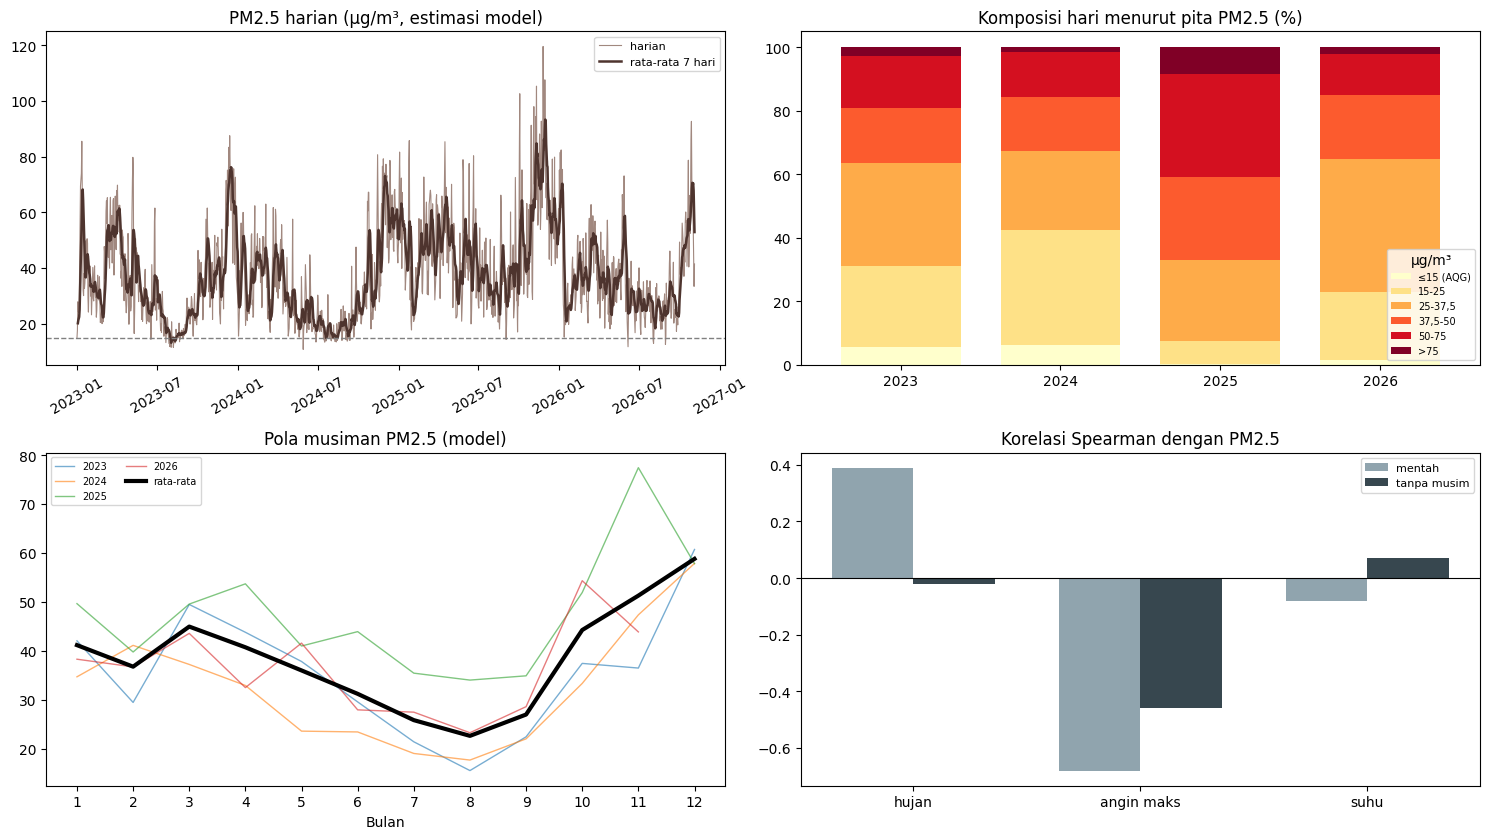

In [ ]:
# @title 11. Analisis PM2.5: pita WHO, musiman, hujan/angin dengan kontrol musim
f_aq, f_cu = CLEAN / "openmeteo_aq_harian.csv", CLEAN / "openmeteo_cuaca_harian.csv"
om_daily = pd.DataFrame()

def efek_hujan_dalam_bulan(dj, min_hari=3):
    # Selisih rata-rata PM2.5 (hari hujan - hari kering) di DALAM tiap bulan
    rows = []
    for ym, g in dj.groupby("ym"):
        h = g[g["precipitation_sum"] >= 1]["pm2_5_mean"]
        t = g[g["precipitation_sum"] < 1]["pm2_5_mean"]
        if len(h) >= min_hari and len(t) >= min_hari:
            rows.append({"bulan": str(ym), "selisih_hujan_minus_kering": h.mean() - t.mean(),
                         "n_hujan": len(h), "n_kering": len(t)})
    return pd.DataFrame(rows)

if not f_aq.exists():
    print("Belum ada 02_clean/openmeteo_aq_harian.csv. Jalankan sel 9-10.")
else:
    om_daily = pd.read_csv(f_aq)
    om_daily["tanggal"] = pd.to_datetime(om_daily["tanggal"])
    zlist = sorted(om_daily["zona"].unique())

    if len(zlist) > 1:
        pvz = om_daily.pivot_table(index="tanggal", columns="zona", values="pm2_5_mean")
        sel_z = pvz.max(axis=1) - pvz.min(axis=1)
        print(f"Selisih PM2.5 harian antar-zona: rata-rata {sel_z.mean():.3f}, maks {sel_z.max():.3f} µg/m³")
        if sel_z.max() < 0.5:
            print("⚠️ Zona praktis IDENTIK -> jangan memberi label per-wilayah; pakai satu titik.")

    z = zlist[0]
    dz = om_daily[om_daily["zona"] == z].sort_values("tanggal").copy()
    valid = dz[dz["jam_pm25_terisi"] >= 18].copy()
    mulai, akhir = dz["tanggal"].min(), dz["tanggal"].max()
    harapan = (akhir - mulai).days + 1
    print(f"Zona: {z} | PM2.5 ESTIMASI MODEL (bukan pengukuran stasiun)")
    print(f"Jendela: {mulai:%d %b %Y} - {akhir:%d %b %Y} | hari valid {len(valid)}/{harapan} ({len(valid) / harapan * 100:.0f}%)")
    if (akhir - mulai).days < 330:
        print("⚠️ Rentang < 12 bulan: JANGAN digeneralisasi sebagai pola setahun/musiman.")

    valid["tahun"] = valid["tanggal"].dt.year
    valid["bln"] = valid["tanggal"].dt.month
    valid["ym"] = valid["tanggal"].dt.to_period("M")
    valid["pita"] = pd.cut(valid["pm2_5_mean"], bins=PITA_PM25, labels=LABEL_PITA)

    ring = pd.DataFrame({
        "rata2": [valid["pm2_5_mean"].mean()], "median": [valid["pm2_5_mean"].median()],
        "p95": [valid["pm2_5_mean"].quantile(0.95)], "maks_harian": [valid["pm2_5_mean"].max()],
        "hari_>15": [int(valid["pm25_lebih_who_15"].sum())],
        "hari_>55": [int(valid["pm25_lebih_baku_idn_55"].sum())], "hari_valid": [len(valid)]}).round(1)
    display(ring)
    ring.to_csv(ANALYSIS / "openmeteo_ringkasan_pm25.csv", index=False)

    tab_pita = (pd.crosstab(valid["tahun"], valid["pita"], normalize="index") * 100).round(1)
    print("Persentase hari per pita PM2.5 (µg/m³) per tahun — pita WHO 2021 (verifikasi sebelum dikutip):")
    display(tab_pita)
    tab_pita.to_csv(ANALYSIS / "openmeteo_pita_pm25_tahunan.csv")

    musim = valid.groupby(["tahun", "bln"])["pm2_5_mean"].mean().unstack("tahun")
    musim["rata2_semua_tahun"] = musim.mean(axis=1)
    musim.round(1).to_csv(ANALYSIS / "openmeteo_pola_musiman.csv")
    print("Pola musiman (rata-rata PM2.5 per bulan kalender):")
    display(musim.round(1))

    fig, ax = plt.subplots(2, 2, figsize=(15, 8.5))
    ax = ax.ravel()
    ax[0].plot(valid["tanggal"], valid["pm2_5_mean"], lw=0.8, color="#a1887f", label="harian")
    ax[0].plot(valid["tanggal"], valid["pm2_5_mean"].rolling(7, min_periods=3).mean(), lw=1.8, color="#4e342e", label="rata-rata 7 hari")
    ax[0].axhline(PM25_WHO_24H, ls="--", c="gray", lw=1)
    ax[0].set_title("PM2.5 harian (µg/m³, estimasi model)"); ax[0].legend(fontsize=8)
    ax[0].tick_params(axis="x", rotation=30)

    tab_pita.plot(kind="bar", stacked=True, ax=ax[1], colormap="YlOrRd", width=0.75)
    ax[1].set_title("Komposisi hari menurut pita PM2.5 (%)"); ax[1].set_xlabel("")
    ax[1].legend(fontsize=7, title="µg/m³"); ax[1].tick_params(axis="x", rotation=0)

    for th in musim.columns[:-1]:
        ax[2].plot(musim.index, musim[th], lw=1, alpha=0.6, label=str(th))
    ax[2].plot(musim.index, musim["rata2_semua_tahun"], lw=3, color="black", label="rata-rata")
    ax[2].set_xticks(range(1, 13)); ax[2].set_xlabel("Bulan")
    ax[2].set_title("Pola musiman PM2.5 (model)"); ax[2].legend(fontsize=7, ncol=2)

    # --- Hujan & angin dengan kontrol musim
    dj = pd.DataFrame()
    if f_cu.exists():
        cu = pd.read_csv(f_cu)
        cu["tanggal"] = pd.to_datetime(cu["time"])
        dj = valid.merge(cu, on="tanggal", how="inner")
        print(f"\nIrisan PM2.5 x cuaca: {len(dj)} hari")
    if len(dj) >= 60:
        kolom = ["pm2_5_mean", "precipitation_sum", "wind_speed_10m_max", "temperature_2m_mean"]
        mentah = dj[kolom].rank().corr()["pm2_5_mean"].drop("pm2_5_mean")
        anomali = dj[kolom] - dj.groupby("ym")[kolom].transform("mean")
        desain = anomali.rank().corr()["pm2_5_mean"].drop("pm2_5_mean")
        kor = pd.DataFrame({"rho_mentah": mentah, "rho_tanpa_musim (anomali bulanan)": desain}).round(2)
        print("Korelasi Spearman dengan PM2.5 (korelasi, BUKAN sebab-akibat):")
        display(kor)

        efek = efek_hujan_dalam_bulan(dj)
        if not efek.empty:
            sel_col = "selisih_hujan_minus_kering"
            print(f"Efek hujan DI DALAM bulan yang sama ({len(efek)} bulan memenuhi syarat >=3 hari hujan & >=3 hari kering):")
            print(f"  rata-rata selisih {efek[sel_col].mean():+.1f} µg/m³ | median {efek[sel_col].median():+.1f} | "
                  f"bulan dengan selisih positif: {(efek[sel_col] > 0).mean() * 100:.0f}%")
            print("  Selisih mentah (tanpa kontrol musim): "
                  f"{dj[dj['precipitation_sum'] >= 1]['pm2_5_mean'].mean() - dj[dj['precipitation_sum'] < 1]['pm2_5_mean'].mean():+.1f} µg/m³")
            print("  -> Bila selisih dalam-bulan jauh lebih kecil/berbalik dibanding selisih mentah, efek 'hujan' sebagian besar adalah efek musim.")
            efek.to_csv(ANALYSIS / "openmeteo_efek_hujan_dalam_bulan.csv", index=False)
        x = np.arange(len(kor))
        ax[3].bar(x - 0.18, kor["rho_mentah"], width=0.36, label="mentah", color="#90a4ae")
        ax[3].bar(x + 0.18, kor["rho_tanpa_musim (anomali bulanan)"], width=0.36, label="tanpa musim", color="#37474f")
        ax[3].set_xticks(x); ax[3].set_xticklabels(["hujan", "angin maks", "suhu"], rotation=0)
        ax[3].axhline(0, c="black", lw=0.8); ax[3].legend(fontsize=8)
        ax[3].set_title("Korelasi Spearman dengan PM2.5")
    else:
        ax[3].axis("off")
        print("Irisan PM2.5 x cuaca < 60 hari: analisis hujan/angin dilewati (pastikan cuaca mencakup jendela PM2.5, sel 10).")
    plt.tight_layout(); plt.show()

## 12. (Opsional) Validasi model terhadap data stasiun
Setelah PPID membalas (atau kamu punya data PM2.5 harian stasiun mana pun), simpan sebagai **`01_raw/validasi/pm25_stasiun.csv`** dengan kolom tanggal (`tanggal`/`date`/`waktu`) dan PM2.5 harian (`pm25`/`pm2_5`/`pm_25`). Sel ini menghitung bias dan galat model. **Tanpa validasi, angka PM2.5 model jangan dijadikan headline.**

In [ ]:
# @title 12. Validasi model vs stasiun (Diperbaiki & Otomatis Fetch OpenAQ / Fallback SPKUA)
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Pastikan path RAW & ANALYSIS ada
RAW = globals().get("RAW", Path("01_raw"))
ANALYSIS = globals().get("ANALYSIS", Path("03_analysis"))
START_YEAR = globals().get("START_YEAR", 2023)

f_val = RAW / "validasi" / "pm25_stasiun.csv"
om_daily = globals().get("om_daily", pd.DataFrame())

def bersihkan_kolom(c):
    return str(c).strip().lower().replace("_", "").replace(" ", "").replace("-", "")

def cari_kolom(df, kandidat):
    peta = {bersihkan_kolom(c): c for c in df.columns}
    for k in kandidat:
        if bersihkan_kolom(k) in peta:
            return peta[bersihkan_kolom(k)]
    return None

def fetch_openaq_surabaya():
    """Mengambil data PM2.5 riil Surabaya dari OpenAQ API jika file stasiun lokal kosong."""
    print(" Mencoba mengambil data PM2.5 stasiun riil dari OpenAQ API (Surabaya)...")
    url = "https://api.openaq.org/v2/measurements"
    params = {
        "city": "Surabaya",
        "parameter": "pm25",
        "limit": 10000,
        "date_from": f"{START_YEAR}-01-01"
    }
    headers = {"User-Agent": "Mozilla/5.0"}
    try:
        r = requests.get(url, params=params, headers=headers, timeout=15)
        if r.status_code == 200:
            res = r.json().get("results", [])
            if res:
                rows = []
                for item in res:
                    rows.append({
                        "tanggal": item.get("date", {}).get("local", "")[:10],
                        "pm25": item.get("value")
                    })
                df_openaq = pd.DataFrame(rows)
                df_openaq["tanggal"] = pd.to_datetime(df_openaq["tanggal"])
                df_openaq = df_openaq.groupby("tanggal", as_index=False)["pm25"].mean()

                f_val.parent.mkdir(parents=True, exist_ok=True)
                df_openaq.to_csv(f_val, index=False)
                print(f" Berhasil mengunduh {len(df_openaq)} hari data stasiun riil dari OpenAQ!")
                return True
    except Exception as e:
        print(f" [OpenAQ Fetch Fail] {e}")
    return False

def fallback_spkua_lokal():
    """Fallback menggunakan data SPKUA Kebonsari/Wonorejo jika OpenAQ tidak ada."""
    print(" Mencoba fallback menggunakan data SPKUA lokal Pemkot Surabaya...")
    df_spkua = globals().get("df_spkua", pd.DataFrame())
    if not df_spkua.empty:
        col_tgl = cari_kolom(df_spkua, ["tanggal", "date", "waktu"])
        col_pm25 = cari_kolom(df_spkua, ["pm25", "pm2_5", "ispu_pm25", "ispu"])

        if col_tgl and col_pm25:
            df_fallback = df_spkua[[col_tgl, col_pm25]].copy()
            df_fallback.columns = ["tanggal", "pm25"]
            df_fallback["tanggal"] = pd.to_datetime(df_fallback["tanggal"], errors="coerce")
            df_fallback["pm25"] = pd.to_numeric(df_fallback["pm25"], errors="coerce")
            df_fallback = df_fallback.dropna()

            if not df_fallback.empty:
                f_val.parent.mkdir(parents=True, exist_ok=True)
                df_fallback.to_csv(f_val, index=False)
                print(f" Berhasil menyusun {len(df_fallback)} baris data validasi dari SPKUA lokal!")
                return True
    return False

# 1. Cek ketersediaan file stasiun, jika belum ada coba fetch dari OpenAQ / Fallback SPKUA
if not f_val.exists():
    sukses = fetch_openaq_surabaya()
    if not sukses:
        fallback_spkua_lokal()

# 2. Proses Analisis Validasi
if om_daily.empty:
    print(" Jalankan sel 10-11 dulu (data model Open-Meteo belum dimuat di memori).")
elif not f_val.exists():
    print(f" Data stasiun ({f_val.name}) belum tersedia dan API/Fallback tidak menemukan data. Sel validasi di-skip.")
else:
    try:
        obs = pd.read_csv(f_val, sep=None, engine="python", encoding="utf-8-sig")
        ct = cari_kolom(obs, ["tanggal", "date", "waktu", "time", "utc"])
        cp = cari_kolom(obs, ["pm25", "pm2_5", "pm_25", "value", "konsentrasi"])

        if not ct or not cp:
            print(" Kolom tanggal/pm25 tidak ditemukan. Kolom tersedia:", list(obs.columns))
        else:
            obs = pd.DataFrame({
                "tanggal": pd.to_datetime(obs[ct], errors="coerce"),
                "pm25_obs": pd.to_numeric(obs[cp], errors="coerce")
            }).dropna()

            # Agregasi harian jika data berupa per-jam
            obs["tanggal"] = obs["tanggal"].dt.normalize()
            obs = obs.groupby("tanggal", as_index=False)["pm25_obs"].mean()

            # Irisan dengan data model Open-Meteo
            mod = om_daily.copy()
            if "jam_pm25_terisi" in mod.columns:
                mod = mod[mod["jam_pm25_terisi"] >= 18]

            if "zona" in mod.columns:
                mod = mod[mod["zona"] == mod["zona"].iloc[0]]

            mod["tanggal"] = pd.to_datetime(mod["tanggal"])

            v = obs.merge(mod, on="tanggal", how="inner")

            if len(v) < 5:
                print(f" Irisan data hanya {len(v)} hari (terlalu sedikit untuk statistik validasi). Perlu lebih banyak sampel tanggal yang cocok.")
            else:
                # Perhitungan Metrik Evaluasi Model (Syntax Diperbaiki)
                bias = (v["pm2_5_mean"] - v["pm25_obs"]).mean()
                rmse = np.sqrt(((v["pm2_5_mean"] - v["pm25_obs"]) ** 2).mean())
                mae = (v["pm2_5_mean"] - v["pm25_obs"]).abs().mean()

                r_p = v[["pm2_5_mean", "pm25_obs"]].corr().iloc[0, 1]
                r_s = v[["pm2_5_mean", "pm25_obs"]].rank().corr().iloc[0, 1]

                hasil = pd.DataFrame({
                    "n_hari": [len(v)],
                    "rata2_obs_stasiun": [v["pm25_obs"].mean()],
                    "rata2_model": [v["pm2_5_mean"].mean()],
                    "Bias (Model - Obs)": [bias],
                    "MAE": [mae],
                    "RMSE": [rmse],
                    "r_Pearson": [r_p],
                    "rho_Spearman": [r_s]
                })

                print(f"\nHASIL VALIDASI MODEL vs STASIUN RIIL ({len(v)} HARI IRISAN):")
                display(hasil.round(2))

                ANALYSIS.mkdir(parents=True, exist_ok=True)
                hasil.to_csv(ANALYSIS / "validasi_model_vs_stasiun.csv", index=False)

                # Visualisasi Scatter Plot (Syntax Diperbaiki)
                plt.figure(figsize=(5.5, 5))
                plt.scatter(v["pm25_obs"], v["pm2_5_mean"], s=15, alpha=0.6, color="#2b5c8f", edgecolors="none")

                lim_max = max(v["pm25_obs"].max(), v["pm2_5_mean"].max()) * 1.1
                lim = [0, lim_max]

                plt.plot(lim, lim, "r--", lw=1.5, label="Garis Ideal (1:1)")
                plt.xlim(lim)
                plt.ylim(lim)
                plt.xlabel("PM2.5 Stasiun Lapangan (µg/m³)")
                plt.ylabel("PM2.5 Model Open-Meteo (µg/m³)")
                plt.title(f"Validasi Model vs Stasiun (r = {r_p:.2f})")
                plt.legend()
                plt.grid(True, linestyle=":", alpha=0.6)
                plt.tight_layout()
                plt.show()

    except Exception as e:
        print(f" Gagal memproses validasi: {e}")

 Mencoba mengambil data PM2.5 stasiun riil dari OpenAQ API (Surabaya)...
 Mencoba fallback menggunakan data SPKUA lokal Pemkot Surabaya...
 Data stasiun (pm25_stasiun.csv) belum tersedia dan API/Fallback tidak menemukan data. Sel validasi di-skip.


In [ ]:
# @title 13. Matriks ketersediaan data + irisan tahun yang layak
rth = globals().get("rth", pd.DataFrame())
spk = globals().get("spk", pd.DataFrame())
om_daily = globals().get("om_daily", pd.DataFrame())
f_cu = CLEAN / "openmeteo_cuaca_harian.csv"

tahun_rng = list(range(min(START_YEAR, 2021), END_YEAR + 1))
baris = {}

def sel(n, penuh=None, satuan=""):
    if not n:
        return "❌"
    if penuh and n >= penuh:
        return f"✅ {n}{satuan}"
    return f"🟡 {n}{satuan}"

def hari_target(t):
    if t == date.today().year:
        return (date.today() - date(t, 1, 1)).days + 1
    return 366 if (t % 4 == 0 and (t % 100 != 0 or t % 400 == 0)) else 365

if not rth.empty:
    per_th = rth["data_tahun"].astype(int).value_counts()
    baris["RTH total kota (periode)"] = [sel(int(per_th.get(t, 0))) for t in tahun_rng]
else:
    baris["RTH total kota (periode)"] = ["❌"] * len(tahun_rng)

spk_ok_tahun = set()
if not spk.empty:
    cak_m = cakupan_spkua(spk)
    cak_m["th"] = cak_m["periode"].dt.year
    lokasi_list = sorted(cak_m["lokasi"].unique())
    memadai_per_lok = {}
    for lok in lokasi_list:
        s_ = cak_m[(cak_m["lokasi"] == lok) & (cak_m["memadai"])].groupby("th").size()
        memadai_per_lok[lok] = s_
        baris[f"{lok} (bln ≥{MIN_OBS_BULAN_SPKUA} hr)"] = [sel(int(s_.get(t, 0)), 12, "/12") for t in tahun_rng]
    for t in tahun_rng:
        if lokasi_list and all(memadai_per_lok[l].get(t, 0) >= 9 for l in lokasi_list):
            spk_ok_tahun.add(t)
else:
    baris["SPKUA per stasiun"] = ["❌"] * len(tahun_rng)

om_ok_tahun = set()
if not om_daily.empty:
    zz = om_daily[(om_daily["zona"] == om_daily["zona"].iloc[0]) & (om_daily["jam_pm25_terisi"] >= 18)]
    hv = zz.groupby(zz["tanggal"].dt.year)["tanggal"].nunique()
    baris["Open-Meteo PM2.5 (hari valid)"] = [
        ("❌" if hv.get(t, 0) == 0 else
         (f"✅ {hv[t]} hr" if hv[t] >= 0.95 * hari_target(t) else f"🟡 {hv[t]} hr")) for t in tahun_rng]
    om_ok_tahun = {t for t in tahun_rng if hv.get(t, 0) >= 0.95 * hari_target(t)}
else:
    baris["Open-Meteo PM2.5 (hari valid)"] = ["❌"] * len(tahun_rng)

if f_cu.exists():
    cu_ = pd.read_csv(f_cu)
    n = pd.to_datetime(cu_["time"]).dt.year.value_counts()
    baris["Open-Meteo cuaca (hari)"] = [
        ("❌" if n.get(t, 0) == 0 else
         (f"✅ {n[t]} hr" if n[t] >= 0.95 * (hari_target(t) - (7 if t == date.today().year else 0)) else f"🟡 {n[t]} hr"))
        for t in tahun_rng]
else:
    baris["Open-Meteo cuaca (hari)"] = ["❌"] * len(tahun_rng)

val_ada = (RAW / "validasi" / "pm25_stasiun.csv").exists()
for nama in ["PM2.5 stasiun resmi (PPID DLH)", "Penduduk per kecamatan (BPS)", "RTH per kecamatan"]:
    baris[nama] = ["❓ cek manual"] * len(tahun_rng)

mat = pd.DataFrame(baris, index=[str(t) for t in tahun_rng]).T
mat.to_csv(ANALYSIS / "matriks_ketersediaan.csv")
display(mat)
print("Keterangan: ✅ lengkap | 🟡 sebagian | ❌ tidak ada | ❓ perlu dicek/diminta manual")
print("File validasi stasiun (01_raw/validasi/pm25_stasiun.csv):", "ADA" if val_ada else "belum ada -> PM2.5 model belum tervalidasi")

irisan = sorted(om_ok_tahun & spk_ok_tahun)
print("\nIRISAN TAHUN YANG LAYAK (PM2.5 model lengkap DAN semua stasiun SPKUA memadai >= 9 bulan):",
      irisan if irisan else "tidak ada")
print("Saran: gunakan tahun-tahun irisan untuk perbandingan lintas sumber; untuk sumber lain tulis keterbatasannya di infografis.")

,2021,2022,2023,2024,2025,2026
RTH total kota (periode),❌,❌,❌,❌,🟡 2,❌
SPKUA Kebonsari (bln ≥10 hr),❌,❌,❌,❌,🟡 10/12,❌
SPKUA Wonorejo (bln ≥10 hr),❌,❌,❌,❌,🟡 5/12,❌
Open-Meteo PM2.5 (hari valid),❌,❌,✅ 365 hr,✅ 366 hr,✅ 365 hr,✅ 308 hr
Open-Meteo cuaca (hari),❌,❌,✅ 365 hr,✅ 366 hr,✅ 365 hr,✅ 301 hr
PM2.5 stasiun resmi (PPID DLH),❓ cek manual,❓ cek manual,❓ cek manual,❓ cek manual,❓ cek manual,❓ cek manual
Penduduk per kecamatan (BPS),❓ cek manual,❓ cek manual,❓ cek manual,❓ cek manual,❓ cek manual,❓ cek manual
RTH per kecamatan,❓ cek manual,❓ cek manual,❓ cek manual,❓ cek manual,❓ cek manual,❓ cek manual


Keterangan: ✅ lengkap | 🟡 sebagian | ❌ tidak ada | ❓ perlu dicek/diminta manual
File validasi stasiun (01_raw/validasi/pm25_stasiun.csv): belum ada -> PM2.5 model belum tervalidasi

IRISAN TAHUN YANG LAYAK (PM2.5 model lengkap DAN semua stasiun SPKUA memadai >= 9 bulan): tidak ada
Saran: gunakan tahun-tahun irisan untuk perbandingan lintas sumber; untuk sumber lain tulis keterbatasannya di infografis.


## 14. Generator surat PPID
Mengisi surat permohonan informasi publik **otomatis dari daftar file yang gagal diunduh** (`unduhan_gagal.csv`) ditambah permintaan tetap (RTH per kecamatan, satuan SPKUA, PM2.5 Tandes, alasan frekuensi pengukuran). Isi identitasmu di bawah, jalankan, lalu salin teksnya ke formulir/email PPID DLH Kota Surabaya (cek situs resmi untuk alamat dan formulir terbaru).

In [ ]:
# @title 14. Surat PPID DLH Kota Surabaya
IDENTITAS = {
    "nama": "[NAMA LENGKAP]",
    "status": "[mahasiswa/pelajar/peserta kompetisi]",
    "institusi": "[NAMA SEKOLAH/UNIVERSITAS]",
    "kontak": "[EMAIL / NOMOR WA]",
    "alamat": "[ALAMAT]",
}

NAMA_GRUP = {
    "rth_total": "Jumlah Luas Ruang Terbuka Hijau",
    "taman_kota": "Jumlah Taman Kota dan Luasnya yang Dikelola oleh Pemerintah",
    "akumulasi_rth": "Akumulasi luasan RTH (kebun raya mangrove dan taman hutan raya)",
    "spkua": "Jumlah Stasiun Pemantauan Kualitas Udara Ambien (SPKUA) yang digunakan untuk menentukan ISPU kota",
    "ispu_kategori": "Kualitas Udara menurut Lokasi Pengukuran per Hari",
}
BULAN_NAMA = ["Januari", "Februari", "Maret", "April", "Mei", "Juni", "Juli", "Agustus",
              "September", "Oktober", "November", "Desember"]

def tgl_id(d):
    return f"{d.day} {BULAN_NAMA[d.month - 1]} {d.year}"

def susun_surat(identitas, gagal_df=None):
    butir = []
    if gagal_df is not None and not gagal_df.empty:
        for g, d in gagal_df.groupby("grup"):
            th = sorted({int(x) for x in d["tahun"].dropna()})
            rentang = f"{th[0]}-{th[-1]}" if len(th) > 1 else (str(th[0]) if th else "tahun tidak terbaca")
            butir.append(f"Dataset \"{NAMA_GRUP.get(g, g)}\" periode {rentang} ({len(d)} berkas) yang tidak dapat "
                         f"diunduh dari portal Open Data Surabaya (galat server HTTP 500).")
    butir += [
        "Luas RTH publik per kecamatan (atau per kelurahan) beserta jenisnya (taman, jalur hijau, hutan kota, "
        "lapangan/stadion, makam, dan lainnya) untuk tahun 2022-2025.",
        "Data pemantauan SPKUA: keterangan **satuan dan metode** untuk kolom so2, no2, co, no3, dan parameter_lain "
        "pada dataset SPKUA, termasuk arti parameter \"no3\" dan \"parameter_lain\".",
        "Data harian PM2.5 (dan PM10 bila ada) serta ISPU harian dari seluruh SPKUA (Wonorejo, Kebonsari, Tandes) "
        "periode 2023-2026.",
        "Penjelasan metode/jadwal pengukuran (mengapa jumlah hari pengukuran per bulan berbeda antar-stasiun, "
        "misalnya SPKUA Wonorejo dan SPKUA Kebonsari).",
    ]
    daftar = "\n".join(f"  {i}. {b}" for i, b in enumerate(butir, 1))
    return f"""Surabaya, {tgl_id(date.today())}

Kepada Yth.
Pejabat Pengelola Informasi dan Dokumentasi (PPID)
Dinas Lingkungan Hidup Kota Surabaya
di Surabaya

Perihal: Permohonan Informasi Publik

Dengan hormat,

Saya yang bertanda tangan di bawah ini:
  Nama       : {identitas['nama']}
  Status     : {identitas['status']}
  Institusi  : {identitas['institusi']}
  Alamat     : {identitas['alamat']}
  Kontak     : {identitas['kontak']}

berdasarkan Undang-Undang Nomor 14 Tahun 2008 tentang Keterbukaan Informasi Publik, mengajukan
permohonan informasi berikut:

{daftar}

Tujuan penggunaan: penyusunan karya infografis dalam kompetisi Infographic Data Challenge (IDC) Gelar Rasa
2026 dengan topik "Ketersediaan Ruang Terbuka Hijau (RTH) vs Kualitas Udara di Kota Surabaya"
(non-komersial). Sumber data akan dicantumkan dalam karya.

Format yang diharapkan: berkas digital (CSV/Excel/PDF) melalui email atau tautan unduhan.

Demikian permohonan ini saya sampaikan. Atas perhatian dan kerja sama Bapak/Ibu, saya ucapkan terima kasih.

Hormat saya,


{identitas['nama']}
"""

gagal_df = pd.read_csv(GAGAL_PATH) if GAGAL_PATH.exists() else None
surat = susun_surat(IDENTITAS, gagal_df)
f_surat = ANALYSIS / "surat_PPID_DLH_Surabaya.txt"
f_surat.write_text(surat, encoding="utf-8")
print(surat)
print(f"\nTersimpan: {f_surat}")
if any(v.startswith("[") for v in IDENTITAS.values()):
    print("⚠️ Ganti isian [ ... ] pada IDENTITAS lalu jalankan ulang sel ini sebelum dikirim.")

Surabaya, 4 November 2026

Kepada Yth.
Pejabat Pengelola Informasi dan Dokumentasi (PPID)
Dinas Lingkungan Hidup Kota Surabaya
di Surabaya

Perihal: Permohonan Informasi Publik

Dengan hormat,

Saya yang bertanda tangan di bawah ini:
  Nama       : [NAMA LENGKAP]
  Status     : [mahasiswa/pelajar/peserta kompetisi]
  Institusi  : [NAMA SEKOLAH/UNIVERSITAS]
  Alamat     : [ALAMAT]
  Kontak     : [EMAIL / NOMOR WA]

berdasarkan Undang-Undang Nomor 14 Tahun 2008 tentang Keterbukaan Informasi Publik, mengajukan
permohonan informasi berikut:

  1. Dataset "Kualitas Udara menurut Lokasi Pengukuran per Hari" periode 2023-2024 (30 berkas) yang tidak dapat diunduh dari portal Open Data Surabaya (galat server HTTP 500).
  2. Dataset "Jumlah Luas Ruang Terbuka Hijau" periode 2022-2025 (14 berkas) yang tidak dapat diunduh dari portal Open Data Surabaya (galat server HTTP 500).
  3. Dataset "Jumlah Stasiun Pemantauan Kualitas Udara Ambien (SPKUA) yang digunakan untuk menentukan ISPU kota" periode 2

In [ ]:
# @title 15. Ekspor semua hasil ke ZIP
arsip = shutil.make_archive(str(BASE_DIR.parent / "IDC_RTH_Surabaya_hasil"), "zip", BASE_DIR)
print("ZIP:", arsip)
try:
    from google.colab import files
    files.download(arsip)
except Exception:
    print("(Bukan Colab: ambil ZIP dari path di atas.)")

ZIP: /content/IDC_RTH_Surabaya_hasil.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Yang masih manual
1. **BPS Kota Surabaya** — *Kota Surabaya Dalam Angka* (luas, penduduk, kepadatan per kecamatan). Judul kandidat dari CKAN ada di sel 3.
2. **Kirim surat PPID** (sel 14) dan, setelah balasan, taruh file PM2.5 stasiun di `01_raw/validasi/pm25_stasiun.csv` (sel 12) serta file RTH/taman/ISPU di folder grupnya (sel 5).
3. **Verifikasi ambang & pita PM2.5** (WHO 2021, baku mutu PP 22/2021) sebelum dikutip.
4. Catat semua sumber di `01_raw/data_log.csv` (terisi otomatis) dan cantumkan atribusi *"Weather data by Open-Meteo.com"*.

# Perbaikan dari gemini

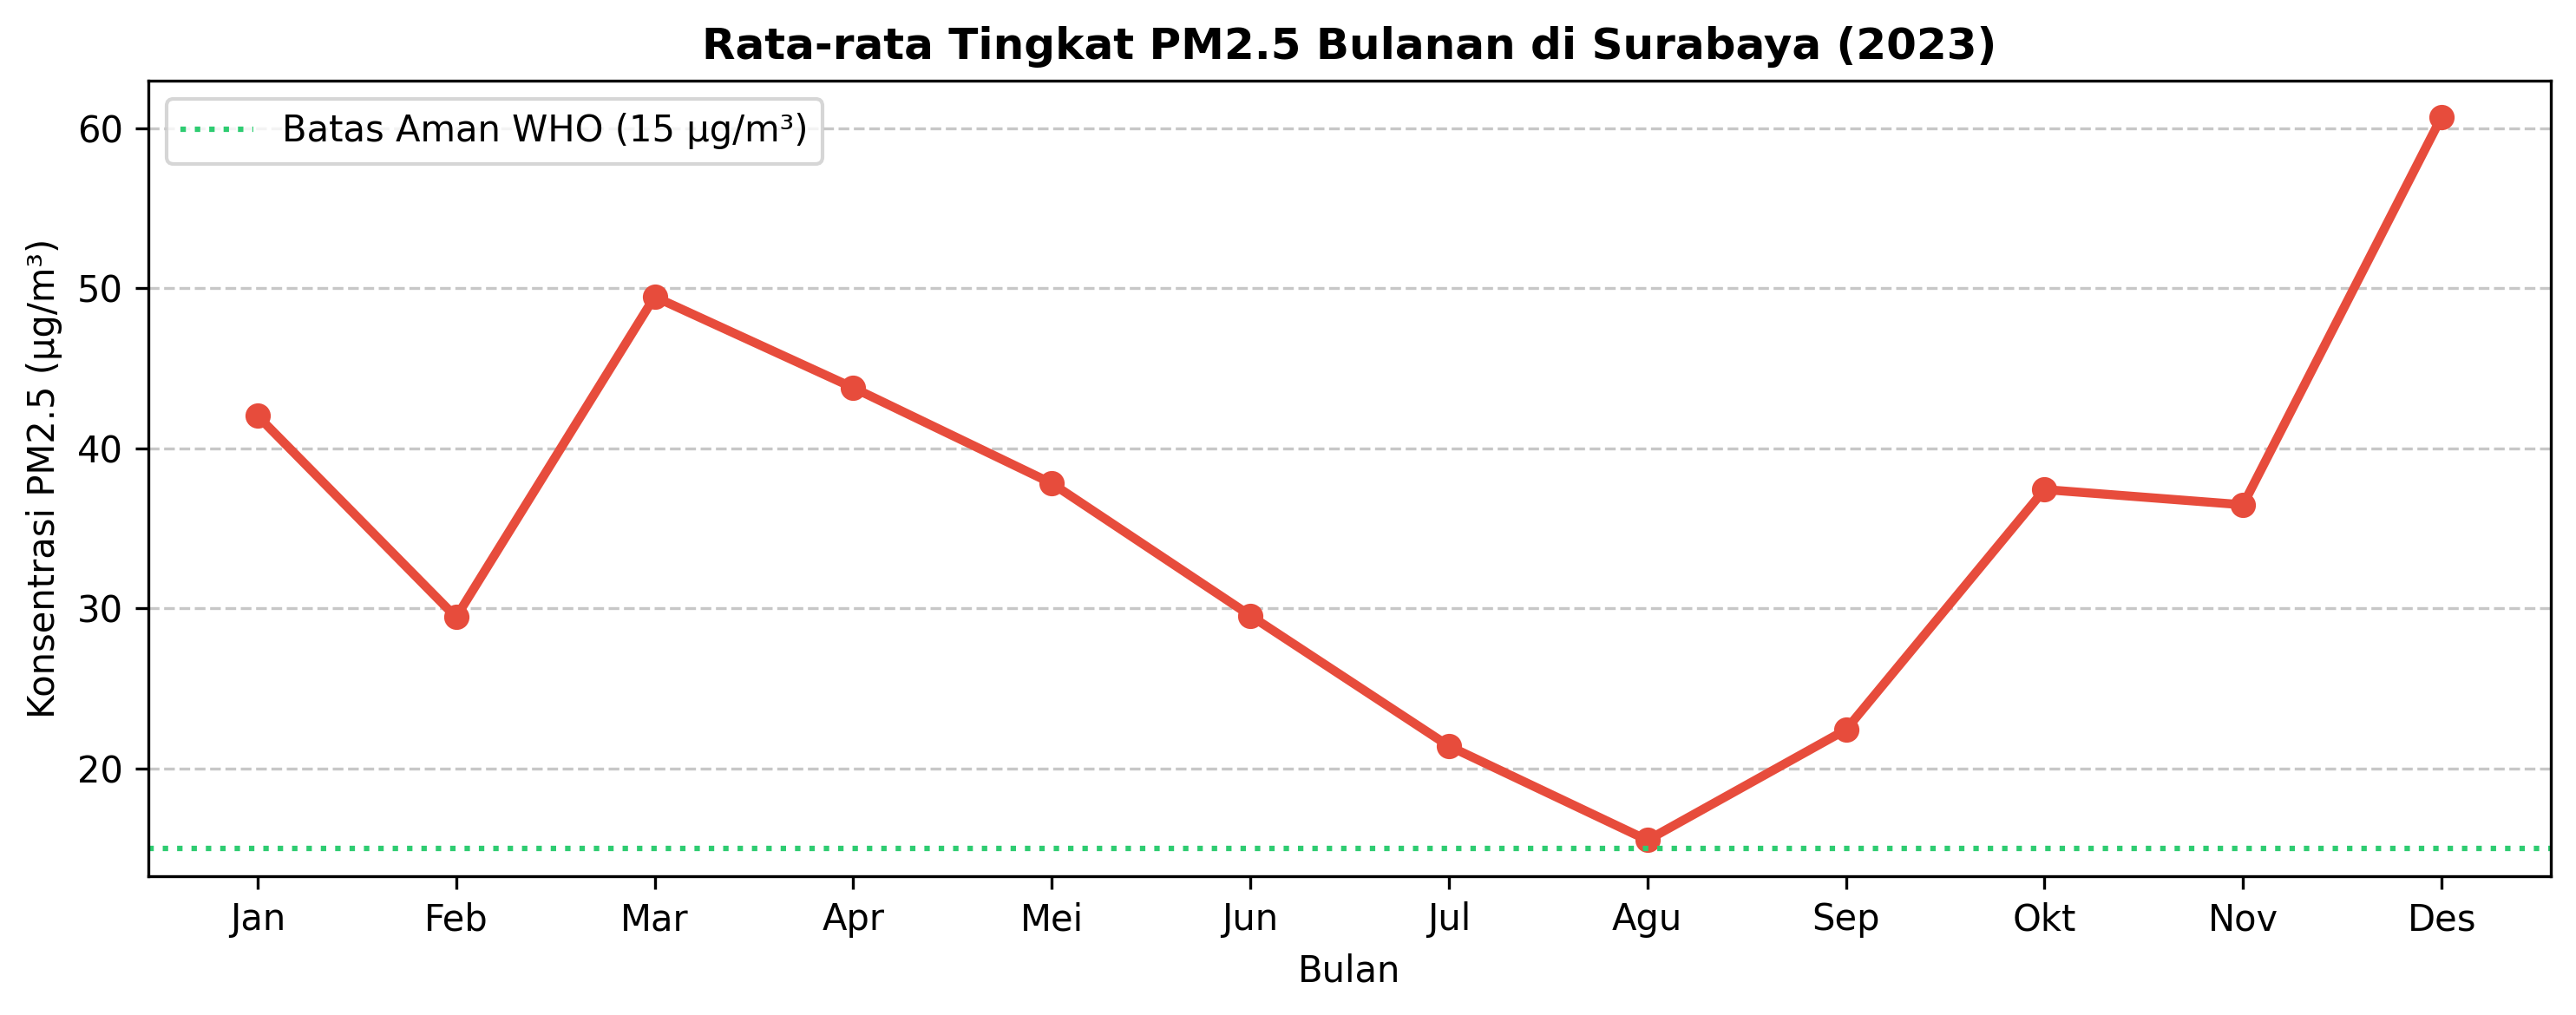

In [ ]:
import pandas as pd
import requests
import matplotlib.pyplot as plt

# 1. Tarik Data PM2.5 Surabaya 2023 dari Open-Meteo
url = "https://air-quality-api.open-meteo.com/v1/air-quality"
params = {
    "latitude": -7.2575,
    "longitude": 112.7521,
    "hourly": "pm2_5",
    "start_date": "2023-01-01",
    "end_date": "2023-12-31",
    "timezone": "Asia/Jakarta"
}

res = requests.get(url, params=params)
data = res.json()

# 2. Olah Data
df = pd.DataFrame({
    'datetime': pd.to_datetime(data['hourly']['time']),
    'pm2_5': data['hourly']['pm2_5']
})

# Agregasi Rata-rata Bulanan untuk Infografis
df['month'] = df['datetime'].dt.strftime('%b')
monthly_avg = df.groupby(df['datetime'].dt.month)['pm2_5'].mean()
months = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']

# 3. Plot Grafik Tren Bulanan
plt.figure(figsize=(10, 4), dpi=300)
plt.plot(months, monthly_avg, marker='o', color='#e74c3c', linewidth=2.5)
plt.title('Rata-rata Tingkat PM2.5 Bulanan di Surabaya (2023)', fontsize=12, fontweight='bold')
plt.xlabel('Bulan')
plt.ylabel('Konsentrasi PM2.5 (µg/m³)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.axhline(y=15, color='#2ecc71', linestyle=':', label='Batas Aman WHO (15 µg/m³)')
plt.legend()
plt.tight_layout()
plt.show()